In [3]:
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsRegressor, KNeighborsClassifier
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.model_selection import *
from sklearn.preprocessing import *
from sklearn.compose import *
from sklearn.metrics import *
import numpy as np
from plotnine import *
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.model_selection import GridSearchCV
from sklearn.impute import SimpleImputer
from sklearn.metrics import confusion_matrix
from sklearn.svm import SVC

In [4]:
herb = 'https://www.dropbox.com/s/s2a1uoiegitupjc/cannabis_full.csv?dl=1'
herb_df = pd.read_csv(herb)
herb_df.head()

,Strain,Type,Rating,Effects,Flavor,Creative,Energetic,Tingly,Euphoric,Relaxed,...,Ammonia,Minty,Tree,Fruit,Butter,Pineapple,Tar,Rose,Plum,Pear
0,100-Og,hybrid,4.0,"Creative,Energetic,Tingly,Euphoric,Relaxed","Earthy,Sweet,Citrus",1.0,1.0,1.0,1.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,98-White-Widow,hybrid,4.7,"Relaxed,Aroused,Creative,Happy,Energetic","Flowery,Violet,Diesel",1.0,1.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1024,sativa,4.4,"Uplifted,Happy,Relaxed,Energetic,Creative","Spicy/Herbal,Sage,Woody",1.0,1.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,13-Dawgs,hybrid,4.2,"Tingly,Creative,Hungry,Relaxed,Uplifted","Apricot,Citrus,Grapefruit",1.0,0.0,1.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,24K-Gold,hybrid,4.6,"Happy,Relaxed,Euphoric,Uplifted,Talkative","Citrus,Earthy,Orange",0.0,0.0,0.0,1.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [5]:
herb_df.describe()

,Rating,Creative,Energetic,Tingly,Euphoric,Relaxed,Aroused,Happy,Uplifted,Hungry,...,Ammonia,Minty,Tree,Fruit,Butter,Pineapple,Tar,Rose,Plum,Pear
count,2351.000000,2321.000000,2320.000000,2313.000000,2331.000000,2318.000000,2306.000000,2326.000000,2330.000000,2318.000000,...,2305.000000,2305.000000,2305.000000,2305.000000,2305.000000,2305.000000,2305.000000,2305.000000,2305.000000,2305.000000
mean,4.310634,0.321844,0.278448,0.149589,0.701416,0.744607,0.086297,0.804385,0.646781,0.206644,...,0.012148,0.017787,0.014751,0.014751,0.008243,0.018221,0.003471,0.006941,0.000868,0.001302
std,0.836394,0.467284,0.448332,0.356745,0.457735,0.436176,0.280862,0.396759,0.478073,0.404985,...,0.109568,0.132207,0.120579,0.120579,0.090435,0.133780,0.058823,0.083044,0.029450,0.036061
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,4.200000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,4.400000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,4.700000,1.000000,1.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,5.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


**PART 1**
**This is to get a dataframe that only has sativa and indica for type.**

In [6]:
pt1_df = herb_df.copy()
pt1_df = pt1_df[pt1_df['Type'].isin(['sativa', 'indica'])]
pt1_df.head()

,Strain,Type,Rating,Effects,Flavor,Creative,Energetic,Tingly,Euphoric,Relaxed,...,Ammonia,Minty,Tree,Fruit,Butter,Pineapple,Tar,Rose,Plum,Pear
2,1024,sativa,4.4,"Uplifted,Happy,Relaxed,Energetic,Creative","Spicy/Herbal,Sage,Woody",1.0,1.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,3-Bears-Og,indica,0.0,NaN,NaN,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7,303-Og,indica,4.2,"Relaxed,Happy,Euphoric,Uplifted,Giggly","Citrus,Pungent,Earthy",0.0,0.0,0.0,1.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
8,3D-Cbd,sativa,4.6,"Uplifted,Focused,Happy,Talkative,Relaxed","Earthy,Woody,Flowery",0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9,3X-Crazy,indica,4.4,"Relaxed,Tingly,Happy,Euphoric,Uplifted","Earthy,Grape,Sweet",0.0,0.0,1.0,1.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [7]:
X = pt1_df.drop(columns=['Strain', 'Type', 'Effects', 'Flavor'])
y = pt1_df['Type']

CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=321)


**For our metric, we will focus on getting the ROC to see the models and their ability to accurately classify the true positives over the true negatives.**

The ROC AUC is useful here because it measures how well each model distinguishes between the cannabis types across all possible classification thresholds, not just at one cutoff. Unlike accuracy or F1, which depend on a specific decision boundary, the ROC AUC gives a broader view of model performance and is especially valuable if the dataset has class imbalance between Indica, Sativa, and Hybrid.

In [8]:
num_features = ["Rating"]
binary_features = X.columns.drop(num_features).tolist()

numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler', StandardScaler())
])

binary_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value=0)) # Changed to constant strategy with fill_value=0
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, num_features),
        ('binary', binary_transformer, binary_features)
    ]
).set_output(transform="pandas")

# Define scoring metrics using make_scorer to handle string labels and suppress warnings
scoring = {
    "ACC": make_scorer(accuracy_score),
    "PREC": make_scorer(precision_score, average='weighted', zero_division=0),
    "REC":  make_scorer(recall_score, average='weighted', zero_division=0),
    "F1": make_scorer(f1_score, average='weighted', zero_division=0),
    "ROC": make_scorer(roc_auc_score, multi_class='ovr', average='weighted', response_method='predict_proba'),
}

**Q1 LDA**

In [9]:
pipe_lda = Pipeline([
    ("ct", preprocessor),
    ("lda", LinearDiscriminantAnalysis())
])

pipe_lda.fit(X,y)

Pipeline(steps=[('ct',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer()),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Rating']),
                                                 ('binary',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value=0,
                                                                                 strategy='constant'))]),
                                                  ['Creative', 'Energetic',
                                                   'Tingly', 'Euphoric',
                                                   'Relaxed', 'Aroused',
                                                   'Happy', 'Uplifted',
                                                   'Hungry', 'Talkative',
                                                   'Giggly', 'Focused',
                                                   'Sleepy', 'Dry', 'Mouth',
                                                   'Earthy', 'Sweet', 'Citrus',
                                                   'Flowery', 'Violet',
                                                   'Diesel', 'Spicy/Herbal',
                                                   'Sage', 'Woody', 'Apricot',
                                                   'Grapefruit', 'Orange',
                                                   'Pungent', 'Grape', 'Pine', ...])])),
                ('lda', LinearDiscriminantAnalysis())])

In [13]:
para_lda = [{
    "lda__solver": ['svd'],
    "lda__shrinkage": [None]
    },
    {
    "lda__solver": ['lsqr'],
    "lda__shrinkage": [None, 'auto', 0.01, 0.1, 0.5, 0.9, 1]
    }]

search_lda = GridSearchCV(pipe_lda, para_lda, cv=CV, scoring=scoring, refit="ROC", n_jobs=-1)
lda_fit = search_lda.fit(X, y)
pd.DataFrame(lda_fit.cv_results_).sort_values(by='rank_test_ROC')

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_lda__shrinkage,param_lda__solver,params,split0_test_ACC,split1_test_ACC,split2_test_ACC,...,std_test_F1,rank_test_F1,split0_test_ROC,split1_test_ROC,split2_test_ROC,split3_test_ROC,split4_test_ROC,mean_test_ROC,std_test_ROC,rank_test_ROC
5,0.044820,0.024407,0.096130,0.041782,0.5,lsqr,"{'lda__shrinkage': 0.5, 'lda__solver': 'lsqr'}",0.833333,0.846491,0.872807,...,0.014977,3,0.919805,0.932508,0.938596,0.916437,0.942405,0.929950,0.010217,1
2,0.059954,0.017976,0.084589,0.014002,auto,lsqr,"{'lda__shrinkage': 'auto', 'lda__solver': 'lsqr'}",0.815789,0.837719,0.872807,...,0.021276,4,0.919643,0.931615,0.935187,0.917086,0.943713,0.929449,0.009900,2
4,0.089002,0.018477,0.138281,0.017303,0.1,lsqr,"{'lda__shrinkage': 0.1, 'lda__solver': 'lsqr'}",0.811404,0.850877,0.859649,...,0.019819,5,0.918831,0.929992,0.936729,0.916112,0.939789,0.928291,0.009425,3
6,0.041866,0.010242,0.069701,0.015580,0.9,lsqr,"{'lda__shrinkage': 0.9, 'lda__solver': 'lsqr'}",0.828947,0.842105,0.868421,...,0.018880,2,0.919075,0.927963,0.933726,0.914651,0.942732,0.927629,0.010070,4
3,0.043712,0.014700,0.062925,0.024434,0.01,lsqr,"{'lda__shrinkage': 0.01, 'lda__solver': 'lsqr'}",0.802632,0.842105,0.864035,...,0.023657,6,0.910877,0.924148,0.934862,0.916356,0.935293,0.924307,0.009754,5
7,0.038317,0.013539,0.080465,0.019682,1,lsqr,"{'lda__shrinkage': 1, 'lda__solver': 'lsqr'}",0.837719,0.842105,0.868421,...,0.014336,1,0.920049,0.920739,0.930398,0.912216,0.937909,0.924262,0.008935,6
0,0.071886,0.024511,0.085378,0.018639,None,svd,"{'lda__shrinkage': None, 'lda__solver': 'svd'}",0.793860,0.842105,0.864035,...,0.025725,7,0.898945,0.921794,0.934375,0.915625,0.932350,0.920618,0.012829,7
1,0.050406,0.021833,0.062791,0.021547,None,lsqr,"{'lda__shrinkage': None, 'lda__solver': 'lsqr'}",0.793860,0.837719,0.864035,...,0.025522,8,0.898945,0.921794,0.934375,0.915625,0.932350,0.920618,0.012829,7


In [14]:
lda_fit.best_estimator_.named_steps['lda']

LinearDiscriminantAnalysis(shrinkage=0.5, solver='lsqr')

In [15]:
lda_best = Pipeline([
    ("ct", preprocessor),
    ("lda", LinearDiscriminantAnalysis(shrinkage=0.5, solver='lsqr'))
])

lda_best.fit(X,y)

Pipeline(steps=[('ct',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer()),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Rating']),
                                                 ('binary',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value=0,
                                                                                 strategy='constant'))]),
                                                  ['Creative', 'Energetic',
                                                   'Tingly', 'Euphoric',
                                                   'Relaxed', 'Aroused',
                                                   'Happy', 'Uplifted',
                                                   'Hungry', 'Talkative',
                                                   'Giggly', 'Focused',
                                                   'Sleepy', 'Dry', 'Mouth',
                                                   'Earthy', 'Sweet', 'Citrus',
                                                   'Flowery', 'Violet',
                                                   'Diesel', 'Spicy/Herbal',
                                                   'Sage', 'Woody', 'Apricot',
                                                   'Grapefruit', 'Orange',
                                                   'Pungent', 'Grape', 'Pine', ...])])),
                ('lda',
                 LinearDiscriminantAnalysis(shrinkage=0.5, solver='lsqr'))])

In [16]:
cv_lda = cross_validate(lda_best, X, y, scoring=scoring, cv=CV, return_train_score=False)

result_lda = pd.Series({
    "ROC_AUC": cv_lda["test_ROC"].mean(),
}, name="LDA Classifier #1 (shrinkage=0.5, solver='lsqr')")

result_lda

,"LDA Classifier #1 (shrinkage=0.5, solver='lsqr')"
ROC_AUC,0.92995


In [17]:
y_proba_lda = cross_val_predict(lda_best, X, y, cv=CV, method="predict_proba")[:,1]
y_pred_lda = cross_val_predict(lda_best, X, y, cv=CV, method="predict")
cm = confusion_matrix(y, y_pred_lda)
cm

array([[621,  78],
       [ 92, 348]])

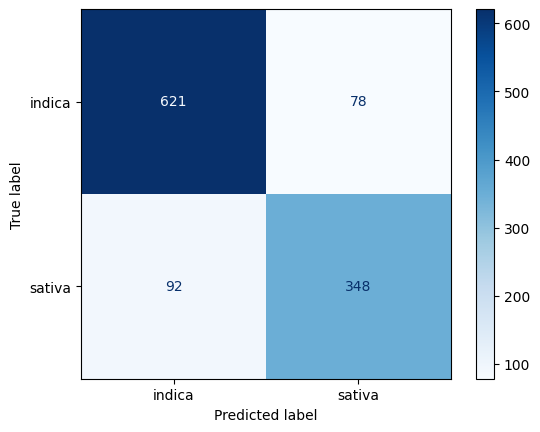

In [18]:
ConfusionMatrixDisplay.from_predictions(y, y_pred_lda, cmap = "Blues")

**Q2 QDA**

In [19]:
pipe_qda = Pipeline([
    ("ct", preprocessor),
    ("qda", QuadraticDiscriminantAnalysis())
])

In [20]:
para_qda = {
    "qda__reg_param": [0.01, 0.1, 0.5, 0.9, 1]
}

search_qda = GridSearchCV(pipe_qda, para_qda, cv=CV, scoring=scoring, refit="ROC", n_jobs=-1)
qda_fit = search_qda.fit(X, y)
pd.DataFrame(qda_fit.cv_results_).sort_values(by='rank_test_ROC')

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_qda__reg_param,params,split0_test_ACC,split1_test_ACC,split2_test_ACC,split3_test_ACC,...,std_test_F1,rank_test_F1,split0_test_ROC,split1_test_ROC,split2_test_ROC,split3_test_ROC,split4_test_ROC,mean_test_ROC,std_test_ROC,rank_test_ROC
4,0.026865,0.003558,0.037983,0.004693,1.00,{'qda__reg_param': 1},0.793860,0.828947,0.837719,0.798246,...,0.021996,3,0.920049,0.920739,0.930398,0.912216,0.937909,0.924262,0.008935,1
3,0.026293,0.001017,0.046962,0.010264,0.90,{'qda__reg_param': 0.9},0.789474,0.820175,0.842105,0.793860,...,0.024645,4,0.918182,0.914326,0.930317,0.902151,0.933085,0.919612,0.011234,2
1,0.025939,0.003460,0.041126,0.001916,0.10,{'qda__reg_param': 0.1},0.820175,0.850877,0.859649,0.833333,...,0.015547,1,0.903977,0.922200,0.933482,0.896794,0.937745,0.918840,0.016063,3
2,0.026643,0.001541,0.040057,0.001618,0.50,{'qda__reg_param': 0.5},0.789474,0.833333,0.877193,0.807018,...,0.033366,2,0.905763,0.910674,0.932670,0.892817,0.929488,0.914282,0.014938,4
0,0.024523,0.001382,0.040559,0.001924,0.01,{'qda__reg_param': 0.01},0.741228,0.802632,0.828947,0.789474,...,0.030115,5,0.832549,0.857670,0.893791,0.867411,0.865476,0.863379,0.019640,5


In [21]:
qda_fit.best_estimator_.named_steps['qda']

QuadraticDiscriminantAnalysis(reg_param=1)

In [22]:
qda_best = Pipeline([
    ("ct", preprocessor),
    ("qda", QuadraticDiscriminantAnalysis(reg_param=1))
])

qda_best.fit(X,y)

Pipeline(steps=[('ct',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer()),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Rating']),
                                                 ('binary',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value=0,
                                                                                 strategy='constant'))]),
                                                  ['Creative', 'Energetic',
                                                   'Tingly', 'Euphoric',
                                                   'Relaxed', 'Aroused',
                                                   'Happy', 'Uplifted',
                                                   'Hungry', 'Talkative',
                                                   'Giggly', 'Focused',
                                                   'Sleepy', 'Dry', 'Mouth',
                                                   'Earthy', 'Sweet', 'Citrus',
                                                   'Flowery', 'Violet',
                                                   'Diesel', 'Spicy/Herbal',
                                                   'Sage', 'Woody', 'Apricot',
                                                   'Grapefruit', 'Orange',
                                                   'Pungent', 'Grape', 'Pine', ...])])),
                ('qda', QuadraticDiscriminantAnalysis(reg_param=1))])

In [23]:
cv_qda = cross_validate(qda_best, X, y, scoring=scoring, cv=CV, return_train_score=False)

result_qda = pd.Series({
    "ROC_AUC": cv_qda["test_ROC"].mean(),
}, name="QDA Classifier #1 (reg_param=1)")

result_qda

,QDA Classifier #1 (reg_param=1)
ROC_AUC,0.924262


In [24]:
y_proba_qda = cross_val_predict(qda_best, X, y, cv=CV, method="predict_proba")[:,1]
y_pred_qda = cross_val_predict(qda_best, X, y, cv=CV, method="predict")
cm2 = confusion_matrix(y, y_pred_qda)
cm2

array([[659,  40],
       [168, 272]])

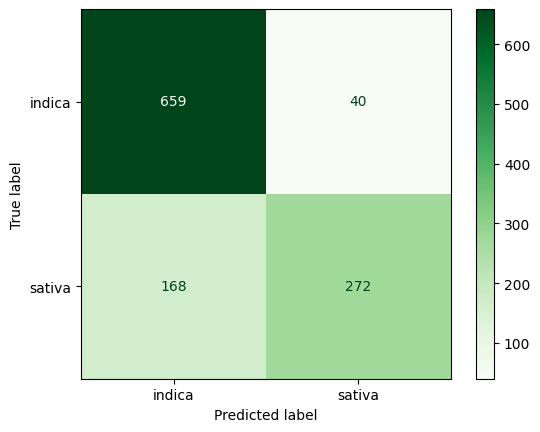

In [25]:
ConfusionMatrixDisplay.from_predictions(y, y_pred_qda, cmap = "Greens")

**Q3 SVC**

In [26]:
pipe_svc = Pipeline([
    ("ct", preprocessor),
    ("svc", SVC(probability=True))
])

pipe_svc.fit(X,y)

Pipeline(steps=[('ct',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer()),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Rating']),
                                                 ('binary',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value=0,
                                                                                 strategy='constant'))]),
                                                  ['Creative', 'Energetic',
                                                   'Tingly', 'Euphoric',
                                                   'Relaxed', 'Aroused',
                                                   'Happy', 'Uplifted',
                                                   'Hungry', 'Talkative',
                                                   'Giggly', 'Focused',
                                                   'Sleepy', 'Dry', 'Mouth',
                                                   'Earthy', 'Sweet', 'Citrus',
                                                   'Flowery', 'Violet',
                                                   'Diesel', 'Spicy/Herbal',
                                                   'Sage', 'Woody', 'Apricot',
                                                   'Grapefruit', 'Orange',
                                                   'Pungent', 'Grape', 'Pine', ...])])),
                ('svc', SVC(probability=True))])

In [27]:
para_svc = {
    "svc__C": [0.1, 1, 10],
    "svc__kernel": ['linear', 'rbf'],
    "svc__gamma": ['scale']
}

search_svc = GridSearchCV(pipe_svc, para_svc, cv=CV, scoring=scoring, refit="ROC", n_jobs=-1)
svc_fit = search_svc.fit(X, y)
pd.DataFrame(svc_fit.cv_results_).sort_values(by='rank_test_ROC')

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_svc__C,param_svc__gamma,param_svc__kernel,params,split0_test_ACC,split1_test_ACC,...,std_test_F1,rank_test_F1,split0_test_ROC,split1_test_ROC,split2_test_ROC,split3_test_ROC,split4_test_ROC,mean_test_ROC,std_test_ROC,rank_test_ROC
1,0.250634,0.016132,0.068558,0.001843,0.1,scale,rbf,"{'svc__C': 0.1, 'svc__gamma': 'scale', 'svc__k...",0.802632,0.855263,...,0.028651,5,0.908888,0.935755,0.937622,0.916153,0.944612,0.928606,0.013656,1
0,0.121810,0.005942,0.047708,0.001308,0.1,scale,linear,"{'svc__C': 0.1, 'svc__gamma': 'scale', 'svc__k...",0.811404,0.837719,...,0.019920,4,0.906250,0.926664,0.932265,0.915463,0.938726,0.923874,0.011663,2
3,0.182030,0.004141,0.058040,0.003432,1.0,scale,rbf,"{'svc__C': 1, 'svc__gamma': 'scale', 'svc__ker...",0.811404,0.850877,...,0.022879,2,0.903896,0.922200,0.932427,0.914570,0.940688,0.922756,0.012947,3
2,0.136778,0.005344,0.045990,0.007693,1.0,scale,linear,"{'svc__C': 1, 'svc__gamma': 'scale', 'svc__ker...",0.824561,0.850877,...,0.022962,1,0.899513,0.919156,0.927070,0.914813,0.928262,0.917763,0.010398,4
4,0.522596,0.068267,0.049719,0.019056,10.0,scale,linear,"{'svc__C': 10, 'svc__gamma': 'scale', 'svc__ke...",0.811404,0.842105,...,0.023857,3,0.893019,0.915381,0.924067,0.913352,0.923520,0.913868,0.011264,5
5,0.351778,0.034396,0.082801,0.019922,10.0,scale,rbf,"{'svc__C': 10, 'svc__gamma': 'scale', 'svc__ke...",0.789474,0.824561,...,0.022444,6,0.878084,0.890706,0.906372,0.895901,0.901529,0.894518,0.009759,6


In [28]:
svc_fit.best_estimator_.named_steps['svc']

SVC(C=0.1, probability=True)

In [29]:
svc_best = Pipeline([
    ("ct", preprocessor),
    ("svc", SVC(C=0.1, probability=True))
])

svc_best.fit(X,y)

Pipeline(steps=[('ct',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer()),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Rating']),
                                                 ('binary',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value=0,
                                                                                 strategy='constant'))]),
                                                  ['Creative', 'Energetic',
                                                   'Tingly', 'Euphoric',
                                                   'Relaxed', 'Aroused',
                                                   'Happy', 'Uplifted',
                                                   'Hungry', 'Talkative',
                                                   'Giggly', 'Focused',
                                                   'Sleepy', 'Dry', 'Mouth',
                                                   'Earthy', 'Sweet', 'Citrus',
                                                   'Flowery', 'Violet',
                                                   'Diesel', 'Spicy/Herbal',
                                                   'Sage', 'Woody', 'Apricot',
                                                   'Grapefruit', 'Orange',
                                                   'Pungent', 'Grape', 'Pine', ...])])),
                ('svc', SVC(C=0.1, probability=True))])

In [30]:
cv_svc = cross_validate(svc_best, X, y, scoring=scoring, cv=CV, return_train_score=False)

result_svc = pd.Series({
    "ROC_AUC": cv_svc["test_ROC"].mean(),
}, name="SVC Classifier (C=0.1, probability=True)")

result_svc

,"SVC Classifier (C=0.1, probability=True)"
ROC_AUC,0.928638


In [31]:
y_proba_svc = cross_val_predict(svc_best, X, y, cv=CV, method="predict_proba")[:,1]
y_pred_svc = cross_val_predict(svc_best, X, y, cv=CV, method="predict")
cm3 = confusion_matrix(y, y_pred_svc)
cm3

array([[653,  46],
       [139, 301]])

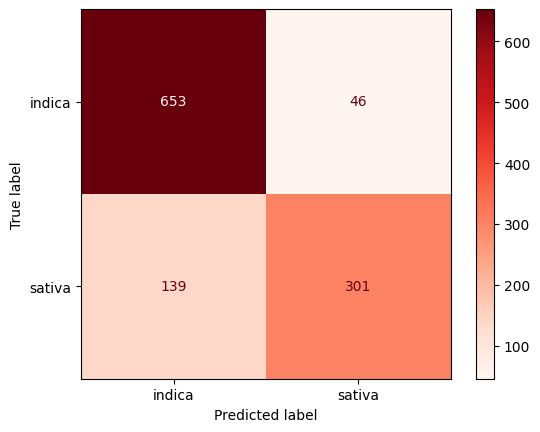

In [32]:
ConfusionMatrixDisplay.from_predictions(y, y_pred_svc, cmap = "Reds")

**Q4 SVM**

In [33]:
pipe_svm = Pipeline([
    ("ct", preprocessor),
    ("svm", SVC(probability=True, kernel='poly'))
])

pipe_svm.fit(X,y)

Pipeline(steps=[('ct',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer()),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Rating']),
                                                 ('binary',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value=0,
                                                                                 strategy='constant'))]),
                                                  ['Creative', 'Energetic',
                                                   'Tingly', 'Euphoric',
                                                   'Relaxed', 'Aroused',
                                                   'Happy', 'Uplifted',
                                                   'Hungry', 'Talkative',
                                                   'Giggly', 'Focused',
                                                   'Sleepy', 'Dry', 'Mouth',
                                                   'Earthy', 'Sweet', 'Citrus',
                                                   'Flowery', 'Violet',
                                                   'Diesel', 'Spicy/Herbal',
                                                   'Sage', 'Woody', 'Apricot',
                                                   'Grapefruit', 'Orange',
                                                   'Pungent', 'Grape', 'Pine', ...])])),
                ('svm', SVC(kernel='poly', probability=True))])

In [34]:
params_svm = {
    "svm__C": [0.1, 1, 10],
    "svm__degree": [2, 3, 4],
    "svm__gamma": ['scale']
}

search_svm = GridSearchCV(pipe_svm, params_svm, cv=CV, scoring=scoring, refit="ROC", n_jobs=-1)
svm_fit = search_svm.fit(X, y)
pd.DataFrame(svm_fit.cv_results_).sort_values(by='rank_test_ROC')

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_svm__C,param_svm__degree,param_svm__gamma,params,split0_test_ACC,split1_test_ACC,...,std_test_F1,rank_test_F1,split0_test_ROC,split1_test_ROC,split2_test_ROC,split3_test_ROC,split4_test_ROC,mean_test_ROC,std_test_ROC,rank_test_ROC
0,0.171068,0.004853,0.049770,0.001199,0.1,2,scale,"{'svm__C': 0.1, 'svm__degree': 2, 'svm__gamma'...",0.802632,0.868421,...,0.031307,2,0.898539,0.939651,0.928287,0.918425,0.944285,0.925838,0.016354,1
1,0.216324,0.044356,0.065874,0.018421,0.1,3,scale,"{'svm__C': 0.1, 'svm__degree': 3, 'svm__gamma'...",0.802632,0.859649,...,0.027684,5,0.890909,0.937459,0.929140,0.912784,0.938318,0.921722,0.017930,2
3,0.207822,0.021987,0.069965,0.015128,1.0,2,scale,"{'svm__C': 1, 'svm__degree': 2, 'svm__gamma': ...",0.807018,0.855263,...,0.022714,1,0.894562,0.928531,0.930032,0.913636,0.940116,0.921375,0.015851,3
2,0.302057,0.037620,0.090575,0.013388,0.1,4,scale,"{'svm__C': 0.1, 'svm__degree': 4, 'svm__gamma'...",0.802632,0.859649,...,0.026018,7,0.888799,0.936161,0.926583,0.919846,0.927853,0.919848,0.016368,4
4,0.151025,0.005429,0.046835,0.002329,1.0,3,scale,"{'svm__C': 1, 'svm__degree': 3, 'svm__gamma': ...",0.811404,0.833333,...,0.017194,3,0.893425,0.921550,0.926177,0.912135,0.929733,0.916604,0.013006,5
5,0.186804,0.013481,0.051607,0.003284,1.0,4,scale,"{'svm__C': 1, 'svm__degree': 4, 'svm__gamma': ...",0.811404,0.846491,...,0.021508,4,0.889123,0.922971,0.923661,0.905722,0.923030,0.912901,0.013687,6
6,0.171936,0.007206,0.046437,0.002843,10.0,2,scale,"{'svm__C': 10, 'svm__degree': 2, 'svm__gamma':...",0.798246,0.837719,...,0.021185,6,0.860877,0.891518,0.915544,0.886972,0.911012,0.893185,0.019509,7
8,0.192279,0.013662,0.045368,0.008425,10.0,4,scale,"{'svm__C': 10, 'svm__degree': 4, 'svm__gamma':...",0.798246,0.802632,...,0.020188,9,0.868831,0.899310,0.890219,0.874432,0.899199,0.886398,0.012625,8
7,0.184204,0.014011,0.049606,0.002595,10.0,3,scale,"{'svm__C': 10, 'svm__degree': 3, 'svm__gamma':...",0.793860,0.807018,...,0.022894,8,0.866477,0.892654,0.903369,0.870373,0.894048,0.885384,0.014382,9


In [35]:
svm_fit.best_estimator_.named_steps['svm']

SVC(C=0.1, degree=2, kernel='poly', probability=True)

In [36]:
svm_best = Pipeline([
    ("ct", preprocessor),
    ("svc", SVC(C=10, degree=2, gamma='auto', kernel='poly', probability=True))
])

svm_best.fit(X,y)

Pipeline(steps=[('ct',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer()),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Rating']),
                                                 ('binary',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value=0,
                                                                                 strategy='constant'))]),
                                                  ['Creative', 'Energetic',
                                                   'Tingly', 'Euphoric',
                                                   'Relaxed', 'Aroused',
                                                   'Happy', 'Uplifted',
                                                   'Hungry', 'Talkative',
                                                   'Giggly', 'Focused',
                                                   'Sleepy', 'Dry', 'Mouth',
                                                   'Earthy', 'Sweet', 'Citrus',
                                                   'Flowery', 'Violet',
                                                   'Diesel', 'Spicy/Herbal',
                                                   'Sage', 'Woody', 'Apricot',
                                                   'Grapefruit', 'Orange',
                                                   'Pungent', 'Grape', 'Pine', ...])])),
                ('svc',
                 SVC(C=10, degree=2, gamma='auto', kernel='poly',
                     probability=True))])

In [37]:
cv_svm = cross_validate(svm_best, X, y, scoring=scoring, cv=CV, return_train_score=False)

result_svm = pd.Series({
    "ROC_AUC": cv_svc["test_ROC"].mean(),
}, name="SVM Classifier (C=10, degree=2, gamma='auto', kernel='poly', probability=True)")

result_svm

,"SVM Classifier (C=10, degree=2, gamma='auto', kernel='poly', probability=True)"
ROC_AUC,0.928638


In [38]:
y_proba_svm = cross_val_predict(svm_best, X, y, cv=CV, method="predict_proba")[:,1]
y_pred_svm = cross_val_predict(svm_best, X, y, cv=CV, method="predict")
cm4 = confusion_matrix(y, y_pred_svm)
cm4

array([[655,  44],
       [134, 306]])

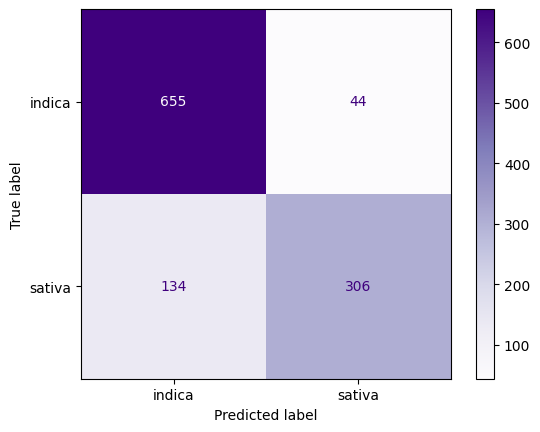

In [39]:
ConfusionMatrixDisplay.from_predictions(y, y_pred_svm, cmap = "Purples")

**This curves tells the positive identification of sativa strains. Given the table below, it looks like LDA was the best performing model based on ROC AUC.**

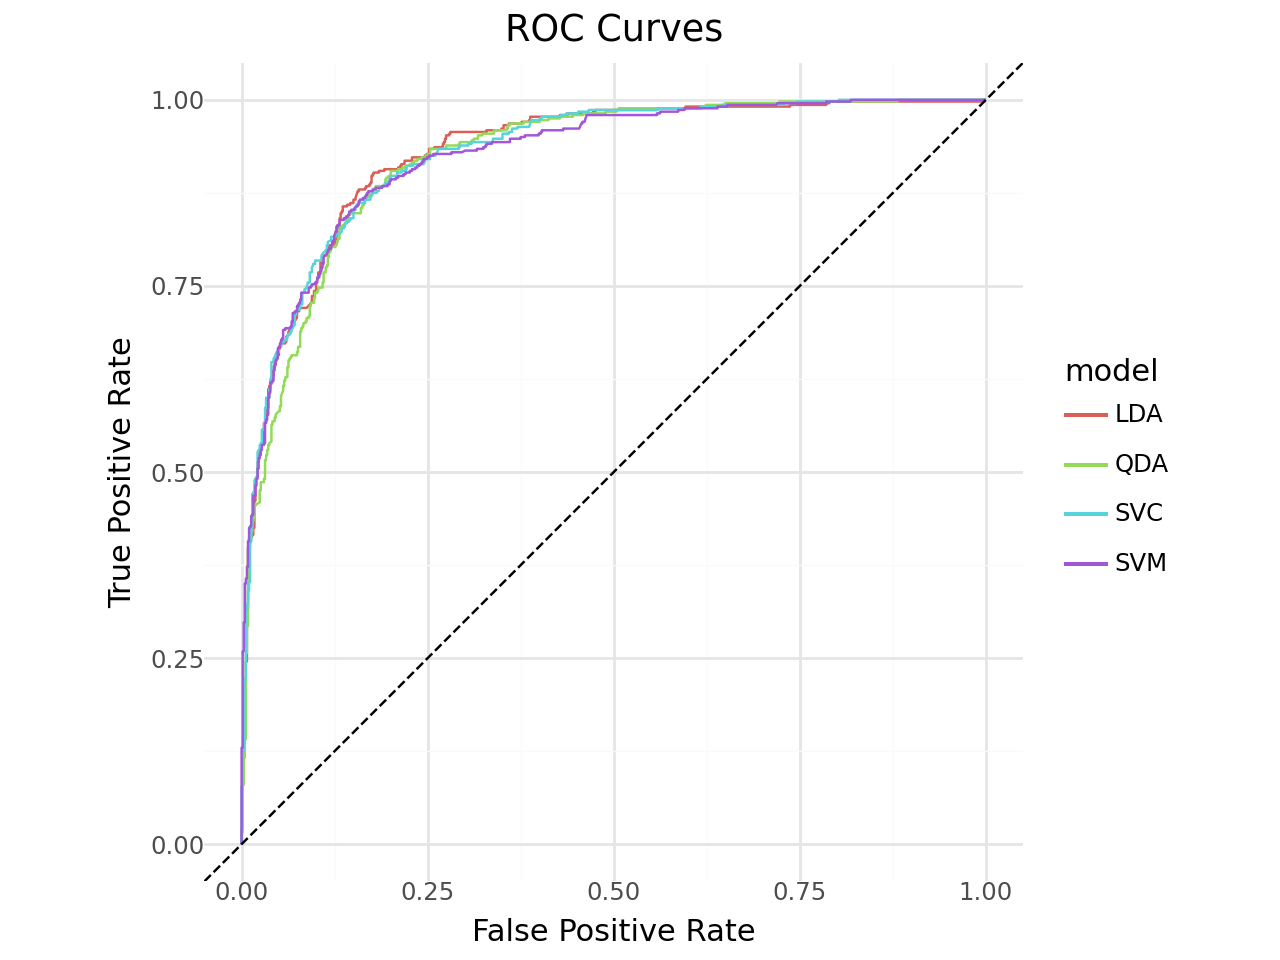

In [40]:
fpr_lda, tpr_lda, _ = roc_curve(y, y_proba_lda, pos_label='sativa')
df_lda = pd.DataFrame({"model": "LDA", "FPR": fpr_lda, "TPR": tpr_lda})

fpr_qda, tpr_qda, _ = roc_curve(y, y_proba_qda, pos_label='sativa')
df_qda = pd.DataFrame({"model": "QDA", "FPR": fpr_qda, "TPR": tpr_qda})

fpr_svc, tpr_svc, _ = roc_curve(y, y_proba_svc, pos_label='sativa')
df_svc = pd.DataFrame({"model": "SVC", "FPR": fpr_svc, "TPR": tpr_svc})

fpr_svm, tpr_svm, _ = roc_curve(y, y_proba_svm, pos_label='sativa')
df_svm = pd.DataFrame({"model": "SVM", "FPR": fpr_svm, "TPR": tpr_svm})

roc_curve_df = pd.concat([df_lda, df_qda, df_svc, df_svm], ignore_index=True)

(ggplot(roc_curve_df, aes("FPR", "TPR", color="model"))
 + geom_path()
 + geom_abline(linetype="dashed")
 + coord_equal()
 + labs(title="ROC Curves", x="False Positive Rate", y="True Positive Rate")
 + theme_minimal())

In [41]:
table = pd.concat([result_lda, result_qda, result_svc, result_svm], axis=1).T
table.sort_values(by='ROC_AUC', ascending=False).style.format({"ROC_AUC": "{:.4f}"})

,ROC_AUC
"LDA Classifier #1 (shrinkage=0.5, solver='lsqr')",0.9300
"SVC Classifier (C=0.1, probability=True)",0.9286
"SVM Classifier (C=10, degree=2, gamma='auto', kernel='poly', probability=True)",0.9286
QDA Classifier #1 (reg_param=1),0.9243


**PART 2**

In [42]:
pt2_df = herb_df.copy()
pt2_df.head()

,Strain,Type,Rating,Effects,Flavor,Creative,Energetic,Tingly,Euphoric,Relaxed,...,Ammonia,Minty,Tree,Fruit,Butter,Pineapple,Tar,Rose,Plum,Pear
0,100-Og,hybrid,4.0,"Creative,Energetic,Tingly,Euphoric,Relaxed","Earthy,Sweet,Citrus",1.0,1.0,1.0,1.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,98-White-Widow,hybrid,4.7,"Relaxed,Aroused,Creative,Happy,Energetic","Flowery,Violet,Diesel",1.0,1.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1024,sativa,4.4,"Uplifted,Happy,Relaxed,Energetic,Creative","Spicy/Herbal,Sage,Woody",1.0,1.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,13-Dawgs,hybrid,4.2,"Tingly,Creative,Hungry,Relaxed,Uplifted","Apricot,Citrus,Grapefruit",1.0,0.0,1.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,24K-Gold,hybrid,4.6,"Happy,Relaxed,Euphoric,Uplifted,Talkative","Citrus,Earthy,Orange",0.0,0.0,0.0,1.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [43]:
X2 = pt2_df.drop(columns=['Strain', 'Type', 'Effects', 'Flavor'])
y2 = pt2_df['Type']

CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=321)

**Q1 Decision Tree**

In [44]:
dt_pipe = Pipeline([
    ('impute', SimpleImputer(strategy='most_frequent')),
    ('dt', DecisionTreeClassifier(random_state=321))
])

dt_pipe.fit(X2,y2)

Pipeline(steps=[('impute', SimpleImputer(strategy='most_frequent')),
                ('dt', DecisionTreeClassifier(random_state=321))])

In [45]:
para_tree = {
    'dt__max_depth': [3, 4, 5, 6, None],
    'dt__min_samples_split': [2, 5, 10, 20],
    'dt__min_samples_leaf': [1, 2, 5, 10]
}

search_dt = GridSearchCV(dt_pipe, para_tree, cv=CV, scoring=scoring, refit="ROC", n_jobs=-1)
dt_fit = search_dt.fit(X2, y2)
pd.DataFrame(dt_fit.cv_results_).sort_values(by='rank_test_ROC')

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_dt__max_depth,param_dt__min_samples_leaf,param_dt__min_samples_split,params,split0_test_ACC,split1_test_ACC,...,std_test_F1,rank_test_F1,split0_test_ROC,split1_test_ROC,split2_test_ROC,split3_test_ROC,split4_test_ROC,mean_test_ROC,std_test_ROC,rank_test_ROC
0,0.049087,0.000865,0.025542,0.002599,3,1,2,"{'dt__max_depth': 3, 'dt__min_samples_leaf': 1...",0.664544,0.604255,...,0.022960,1,0.755767,0.695587,0.721843,0.713554,0.708729,0.719096,0.020214,1
1,0.048534,0.003638,0.025590,0.002141,3,1,5,"{'dt__max_depth': 3, 'dt__min_samples_leaf': 1...",0.664544,0.604255,...,0.022960,1,0.755767,0.695587,0.721843,0.713554,0.708729,0.719096,0.020214,1
2,0.047739,0.000906,0.025263,0.001026,3,1,10,"{'dt__max_depth': 3, 'dt__min_samples_leaf': 1...",0.664544,0.604255,...,0.022960,1,0.755767,0.695587,0.721843,0.713554,0.708729,0.719096,0.020214,1
3,0.048444,0.002081,0.023987,0.002038,3,1,20,"{'dt__max_depth': 3, 'dt__min_samples_leaf': 1...",0.664544,0.604255,...,0.022960,1,0.755767,0.695587,0.721843,0.713554,0.708729,0.719096,0.020214,1
4,0.052275,0.006178,0.027520,0.004038,3,2,2,"{'dt__max_depth': 3, 'dt__min_samples_leaf': 2...",0.664544,0.604255,...,0.022960,1,0.755767,0.695587,0.721843,0.713554,0.708729,0.719096,0.020214,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
66,0.058734,0.001363,0.024886,0.001155,None,1,10,"{'dt__max_depth': None, 'dt__min_samples_leaf'...",0.573248,0.544681,...,0.024931,73,0.657947,0.615861,0.654418,0.640835,0.615461,0.636904,0.018263,76
69,0.062718,0.012273,0.026072,0.001694,None,2,5,"{'dt__max_depth': None, 'dt__min_samples_leaf'...",0.556263,0.527660,...,0.016303,74,0.653967,0.593901,0.650510,0.642349,0.624511,0.633048,0.022065,77
68,0.059486,0.002822,0.024595,0.001061,None,2,2,"{'dt__max_depth': None, 'dt__min_samples_leaf'...",0.545648,0.529787,...,0.018267,78,0.650166,0.608880,0.653335,0.622453,0.622299,0.631426,0.017340,78
65,0.065924,0.008833,0.025305,0.001954,None,1,5,"{'dt__max_depth': None, 'dt__min_samples_leaf'...",0.554140,0.491489,...,0.028327,79,0.644942,0.573215,0.624311,0.625471,0.602856,0.614159,0.024425,79


In [46]:
dt_fit.best_estimator_.named_steps['dt']

DecisionTreeClassifier(max_depth=3, random_state=321)

In [47]:
dt_best = Pipeline([
    ('impute', SimpleImputer(strategy='most_frequent')),
    ('dt', DecisionTreeClassifier(ccp_alpha=0.001, min_samples_leaf=10, random_state=321))
])

dt_best.fit(X2,y2)

Pipeline(steps=[('impute', SimpleImputer(strategy='most_frequent')),
                ('dt',
                 DecisionTreeClassifier(ccp_alpha=0.001, min_samples_leaf=10,
                                        random_state=321))])

In [48]:
cv_dt = cross_validate(dt_best, X2, y2, scoring=scoring, cv=CV, return_train_score=False)

result_dt = pd.Series({
    "ROC_AUC": cv_dt["test_ROC"].mean(),
}, name="DT Classifier (ccp_alpha=0.001, min_samples_leaf=10, random_state=321)")

result_dt

,"DT Classifier (ccp_alpha=0.001, min_samples_leaf=10, random_state=321)"
ROC_AUC,0.721808


In [49]:
y_proba_dt = cross_val_predict(dt_best, X2, y2, cv=CV, method="predict_proba")
y_pred_dt = cross_val_predict(dt_best, X2, y2, cv=CV, method="predict")
cm5 = confusion_matrix(y2, y_pred_dt)
cm5

array([[865, 228, 119],
       [267, 423,   9],
       [282,  24, 134]])

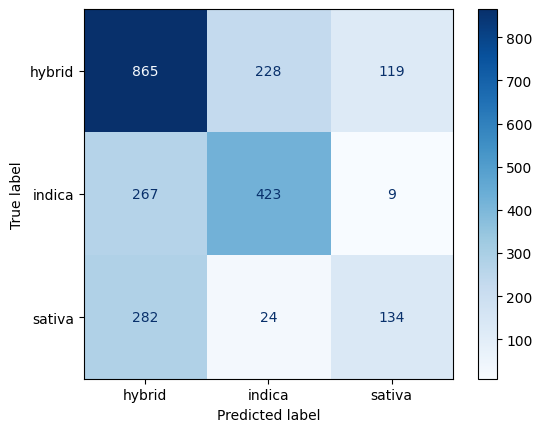

In [50]:
ConfusionMatrixDisplay.from_predictions(y2, y_pred_dt, cmap = "Blues")

**Q2 The model fit for the entire dataset for lda, qda, and knn**

In [51]:
#LDA model

lda_pipe2 = Pipeline([
    ("ct", preprocessor),
    ("lda", LinearDiscriminantAnalysis())
])

lda_pipe2.fit(X2, y2)

Pipeline(steps=[('ct',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer()),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Rating']),
                                                 ('binary',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value=0,
                                                                                 strategy='constant'))]),
                                                  ['Creative', 'Energetic',
                                                   'Tingly', 'Euphoric',
                                                   'Relaxed', 'Aroused',
                                                   'Happy', 'Uplifted',
                                                   'Hungry', 'Talkative',
                                                   'Giggly', 'Focused',
                                                   'Sleepy', 'Dry', 'Mouth',
                                                   'Earthy', 'Sweet', 'Citrus',
                                                   'Flowery', 'Violet',
                                                   'Diesel', 'Spicy/Herbal',
                                                   'Sage', 'Woody', 'Apricot',
                                                   'Grapefruit', 'Orange',
                                                   'Pungent', 'Grape', 'Pine', ...])])),
                ('lda', LinearDiscriminantAnalysis())])

In [52]:
para_lda2 = [{
    "lda__solver": ['svd'],
    "lda__shrinkage": [None]
    },
    {
    "lda__solver": ['lsqr'],
    "lda__shrinkage": [None, 'auto', 0.01, 0.1, 0.5, 0.9, 1]
    }]

search_lda2 = GridSearchCV(lda_pipe2, para_lda2, cv=CV, scoring=scoring, refit="ROC", n_jobs=-1)
lda_fit2 = search_lda2.fit(X, y)
pd.DataFrame(lda_fit2.cv_results_).sort_values(by='rank_test_ROC')

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_lda__shrinkage,param_lda__solver,params,split0_test_ACC,split1_test_ACC,split2_test_ACC,...,std_test_F1,rank_test_F1,split0_test_ROC,split1_test_ROC,split2_test_ROC,split3_test_ROC,split4_test_ROC,mean_test_ROC,std_test_ROC,rank_test_ROC
5,0.024428,0.001207,0.039706,0.001815,0.5,lsqr,"{'lda__shrinkage': 0.5, 'lda__solver': 'lsqr'}",0.833333,0.846491,0.872807,...,0.014977,3,0.919805,0.932508,0.938596,0.916437,0.942405,0.929950,0.010217,1
2,0.026857,0.000987,0.038475,0.001558,auto,lsqr,"{'lda__shrinkage': 'auto', 'lda__solver': 'lsqr'}",0.815789,0.837719,0.872807,...,0.021276,4,0.919643,0.931615,0.935187,0.917086,0.943713,0.929449,0.009900,2
4,0.026898,0.002279,0.039549,0.001624,0.1,lsqr,"{'lda__shrinkage': 0.1, 'lda__solver': 'lsqr'}",0.811404,0.850877,0.859649,...,0.019819,5,0.918831,0.929992,0.936729,0.916112,0.939789,0.928291,0.009425,3
6,0.029190,0.007374,0.044779,0.007083,0.9,lsqr,"{'lda__shrinkage': 0.9, 'lda__solver': 'lsqr'}",0.828947,0.842105,0.868421,...,0.018880,2,0.919075,0.927963,0.933726,0.914651,0.942732,0.927629,0.010070,4
3,0.024473,0.000928,0.041965,0.002537,0.01,lsqr,"{'lda__shrinkage': 0.01, 'lda__solver': 'lsqr'}",0.802632,0.842105,0.864035,...,0.023657,6,0.910877,0.924148,0.934862,0.916356,0.935293,0.924307,0.009754,5
7,0.024183,0.001607,0.038342,0.007784,1,lsqr,"{'lda__shrinkage': 1, 'lda__solver': 'lsqr'}",0.837719,0.842105,0.868421,...,0.014336,1,0.920049,0.920739,0.930398,0.912216,0.937909,0.924262,0.008935,6
0,0.035989,0.010366,0.039454,0.002827,None,svd,"{'lda__shrinkage': None, 'lda__solver': 'svd'}",0.793860,0.842105,0.864035,...,0.025725,7,0.898945,0.921794,0.934375,0.915625,0.932350,0.920618,0.012829,7
1,0.023864,0.001196,0.039752,0.002913,None,lsqr,"{'lda__shrinkage': None, 'lda__solver': 'lsqr'}",0.793860,0.837719,0.864035,...,0.025522,8,0.898945,0.921794,0.934375,0.915625,0.932350,0.920618,0.012829,7


In [53]:
lda_fit2.best_estimator_.named_steps['lda']

LinearDiscriminantAnalysis(shrinkage=0.5, solver='lsqr')

In [54]:
lda_best2 = Pipeline([
    ("ct", preprocessor),
    ("lda", LinearDiscriminantAnalysis(shrinkage=0.5, solver='lsqr'))
])

lda_best2.fit(X2,y2)

Pipeline(steps=[('ct',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer()),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Rating']),
                                                 ('binary',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value=0,
                                                                                 strategy='constant'))]),
                                                  ['Creative', 'Energetic',
                                                   'Tingly', 'Euphoric',
                                                   'Relaxed', 'Aroused',
                                                   'Happy', 'Uplifted',
                                                   'Hungry', 'Talkative',
                                                   'Giggly', 'Focused',
                                                   'Sleepy', 'Dry', 'Mouth',
                                                   'Earthy', 'Sweet', 'Citrus',
                                                   'Flowery', 'Violet',
                                                   'Diesel', 'Spicy/Herbal',
                                                   'Sage', 'Woody', 'Apricot',
                                                   'Grapefruit', 'Orange',
                                                   'Pungent', 'Grape', 'Pine', ...])])),
                ('lda',
                 LinearDiscriminantAnalysis(shrinkage=0.5, solver='lsqr'))])

In [55]:
cv_lda2 = cross_validate(lda_best2, X2, y2, scoring=scoring, cv=CV, return_train_score=False)

result_lda2 = pd.Series({
    "ROC_AUC": cv_lda2["test_ROC"].mean(),
}, name="LDA Classifier #2 (shrinkage=0.5, solver='lsqr')")

result_lda2

,"LDA Classifier #2 (shrinkage=0.5, solver='lsqr')"
ROC_AUC,0.751858


In [56]:
y_proba_lda2 = cross_val_predict(lda_best2, X2, y2, cv=CV, method="predict_proba")
y_pred_lda2 = cross_val_predict(lda_best2, X2, y2, cv=CV, method="predict")
cm6 = confusion_matrix(y2, y_pred_lda2)
cm6

array([[789, 228, 195],
       [215, 464,  20],
       [210,  22, 208]])

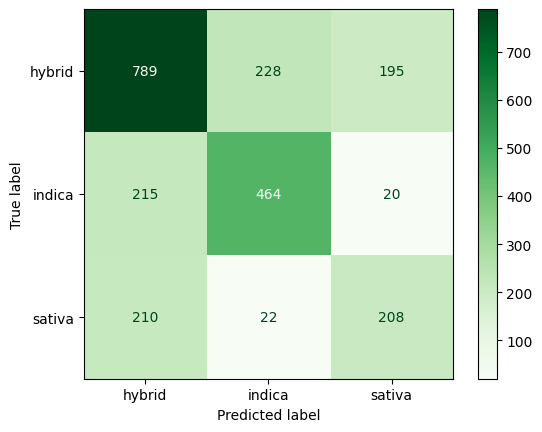

In [57]:
ConfusionMatrixDisplay.from_predictions(y2, y_pred_lda2, cmap = "Greens")

In [58]:
#QDA model

qda_pipe2 = Pipeline([
    ("ct", preprocessor),
    ("qda", QuadraticDiscriminantAnalysis(reg_param=1))
])

qda_pipe2.fit(X2,y2)

Pipeline(steps=[('ct',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer()),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Rating']),
                                                 ('binary',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value=0,
                                                                                 strategy='constant'))]),
                                                  ['Creative', 'Energetic',
                                                   'Tingly', 'Euphoric',
                                                   'Relaxed', 'Aroused',
                                                   'Happy', 'Uplifted',
                                                   'Hungry', 'Talkative',
                                                   'Giggly', 'Focused',
                                                   'Sleepy', 'Dry', 'Mouth',
                                                   'Earthy', 'Sweet', 'Citrus',
                                                   'Flowery', 'Violet',
                                                   'Diesel', 'Spicy/Herbal',
                                                   'Sage', 'Woody', 'Apricot',
                                                   'Grapefruit', 'Orange',
                                                   'Pungent', 'Grape', 'Pine', ...])])),
                ('qda', QuadraticDiscriminantAnalysis(reg_param=1))])

In [59]:
para_qda = {
    "qda__reg_param": [0.01, 0.1, 0.5, 0.9, 1]
}

search_qda2 = GridSearchCV(qda_pipe2, para_qda, cv=CV, scoring=scoring, refit="ROC", n_jobs=-1)
qda_fit2 = search_qda2.fit(X2, y2)
pd.DataFrame(qda_fit2.cv_results_).sort_values(by='rank_test_ROC')

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_qda__reg_param,params,split0_test_ACC,split1_test_ACC,split2_test_ACC,split3_test_ACC,...,std_test_F1,rank_test_F1,split0_test_ROC,split1_test_ROC,split2_test_ROC,split3_test_ROC,split4_test_ROC,mean_test_ROC,std_test_ROC,rank_test_ROC
2,0.043261,0.012622,0.052862,0.006377,0.50,{'qda__reg_param': 0.5},0.651805,0.623404,0.610638,0.610638,...,0.016565,2,0.767533,0.737020,0.755712,0.725358,0.725379,0.742201,0.016839,1
4,0.032727,0.004451,0.044130,0.008071,1.00,{'qda__reg_param': 1},0.562633,0.587234,0.568085,0.546809,...,0.015700,5,0.767562,0.740292,0.748053,0.726937,0.727621,0.742093,0.015011,2
3,0.035809,0.001715,0.051330,0.001830,0.90,{'qda__reg_param': 0.9},0.562633,0.589362,0.570213,0.555319,...,0.012715,4,0.765607,0.738420,0.750904,0.724974,0.725975,0.741176,0.015445,3
1,0.033799,0.001933,0.045667,0.002379,0.10,{'qda__reg_param': 0.1},0.634820,0.585106,0.606383,0.602128,...,0.019260,1,0.756003,0.731430,0.740446,0.726604,0.720041,0.734905,0.012472,4
0,0.035339,0.002192,0.046299,0.001842,0.01,{'qda__reg_param': 0.01},0.556263,0.534043,0.538298,0.525532,...,0.011297,3,0.702612,0.685875,0.683291,0.680545,0.669644,0.684393,0.010655,5


In [60]:
qda_fit2.best_estimator_.named_steps['qda']

QuadraticDiscriminantAnalysis(reg_param=0.5)

In [61]:
qda_best2 = Pipeline([
    ("ct", preprocessor),
    ("qda", QuadraticDiscriminantAnalysis(reg_param=0.5))
])

qda_best2.fit(X2,y2)

Pipeline(steps=[('ct',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer()),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Rating']),
                                                 ('binary',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value=0,
                                                                                 strategy='constant'))]),
                                                  ['Creative', 'Energetic',
                                                   'Tingly', 'Euphoric',
                                                   'Relaxed', 'Aroused',
                                                   'Happy', 'Uplifted',
                                                   'Hungry', 'Talkative',
                                                   'Giggly', 'Focused',
                                                   'Sleepy', 'Dry', 'Mouth',
                                                   'Earthy', 'Sweet', 'Citrus',
                                                   'Flowery', 'Violet',
                                                   'Diesel', 'Spicy/Herbal',
                                                   'Sage', 'Woody', 'Apricot',
                                                   'Grapefruit', 'Orange',
                                                   'Pungent', 'Grape', 'Pine', ...])])),
                ('qda', QuadraticDiscriminantAnalysis(reg_param=0.5))])

In [62]:
cv_qda2 = cross_validate(qda_best2, X2, y2, scoring=scoring, cv=CV, return_train_score=False)

result_qda2 = pd.Series({
    "ROC_AUC": cv_qda2["test_ROC"].mean(),
}, name="QDA Classifier #2 (reg_param=0.5)")

result_qda2

,QDA Classifier #2 (reg_param=0.5)
ROC_AUC,0.742201


In [63]:
y_proba_qda2 = cross_val_predict(qda_best2, X2, y2, cv=CV, method="predict_proba")
y_pred_qda2 = cross_val_predict(qda_best2, X2, y2, cv=CV, method="predict")
cm7 = confusion_matrix(y2, y_pred_qda2)
cm7

array([[1024,  173,   15],
       [ 282,  416,    1],
       [ 408,   11,   21]])

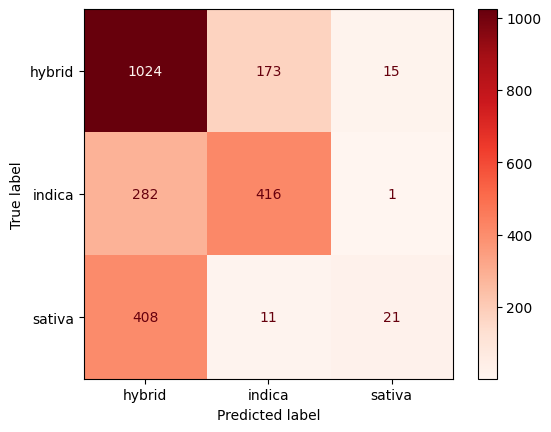

In [64]:
ConfusionMatrixDisplay.from_predictions(y2, y_pred_qda2, cmap = "Reds")

In [65]:
#KNN Classifer model

knn_pipe = Pipeline([
    ("ct", preprocessor),
    ("knn", KNeighborsClassifier())
])

knn_pipe.fit(X2,y2)

Pipeline(steps=[('ct',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer()),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Rating']),
                                                 ('binary',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value=0,
                                                                                 strategy='constant'))]),
                                                  ['Creative', 'Energetic',
                                                   'Tingly', 'Euphoric',
                                                   'Relaxed', 'Aroused',
                                                   'Happy', 'Uplifted',
                                                   'Hungry', 'Talkative',
                                                   'Giggly', 'Focused',
                                                   'Sleepy', 'Dry', 'Mouth',
                                                   'Earthy', 'Sweet', 'Citrus',
                                                   'Flowery', 'Violet',
                                                   'Diesel', 'Spicy/Herbal',
                                                   'Sage', 'Woody', 'Apricot',
                                                   'Grapefruit', 'Orange',
                                                   'Pungent', 'Grape', 'Pine', ...])])),
                ('knn', KNeighborsClassifier())])

In [66]:
para_knn = {
    'knn__n_neighbors': range(1, 10+1),
    'knn__metric': ['manhattan', 'euclidean']
}
search_knn = GridSearchCV(knn_pipe, para_knn, cv=CV, scoring=scoring, refit="ROC", n_jobs=-1)
KNN_fit = search_knn.fit(X2, y2)
pd.DataFrame(KNN_fit.cv_results_).sort_values(by='rank_test_ROC')

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_knn__metric,param_knn__n_neighbors,params,split0_test_ACC,split1_test_ACC,split2_test_ACC,...,std_test_F1,rank_test_F1,split0_test_ROC,split1_test_ROC,split2_test_ROC,split3_test_ROC,split4_test_ROC,mean_test_ROC,std_test_ROC,rank_test_ROC
19,0.021283,0.000545,0.060408,0.006445,euclidean,10,"{'knn__metric': 'euclidean', 'knn__n_neighbors...",0.607219,0.591489,0.574468,...,0.016045,9,0.722644,0.697770,0.709173,0.706469,0.691956,0.705602,0.010502,1
9,0.049784,0.005991,0.307951,0.028008,manhattan,10,"{'knn__metric': 'manhattan', 'knn__n_neighbors...",0.613588,0.589362,0.585106,...,0.013721,5,0.715667,0.696483,0.718066,0.701793,0.688012,0.704004,0.011410,2
18,0.021881,0.002155,0.063762,0.001785,euclidean,9,"{'knn__metric': 'euclidean', 'knn__n_neighbors...",0.602972,0.572340,0.561702,...,0.020812,3,0.718228,0.702763,0.706012,0.704310,0.687897,0.703842,0.009667,3
8,0.026044,0.004787,0.199698,0.035025,manhattan,9,"{'knn__metric': 'manhattan', 'knn__n_neighbors...",0.592357,0.578723,0.563830,...,0.014044,7,0.709319,0.704738,0.706558,0.698405,0.680303,0.699865,0.010418,4
7,0.024266,0.001229,0.175315,0.010823,manhattan,8,"{'knn__metric': 'manhattan', 'knn__n_neighbors...",0.594480,0.574468,0.570213,...,0.010928,8,0.706664,0.692626,0.704346,0.699951,0.683573,0.697432,0.008421,5
17,0.021290,0.001928,0.063886,0.001196,euclidean,8,"{'knn__metric': 'euclidean', 'knn__n_neighbors...",0.585987,0.574468,0.557447,...,0.014322,13,0.709301,0.688726,0.697951,0.697782,0.687085,0.696169,0.007952,6
16,0.026372,0.004626,0.065020,0.004791,euclidean,7,"{'knn__metric': 'euclidean', 'knn__n_neighbors...",0.605096,0.589362,0.563830,...,0.016569,1,0.700062,0.697195,0.690996,0.690385,0.684479,0.692623,0.005481,7
6,0.025893,0.004515,0.166926,0.001082,manhattan,7,"{'knn__metric': 'manhattan', 'knn__n_neighbors...",0.596603,0.582979,0.572340,...,0.010408,2,0.693562,0.696635,0.698834,0.687553,0.682354,0.691788,0.006053,8
4,0.024356,0.001454,0.183393,0.017704,manhattan,5,"{'knn__metric': 'manhattan', 'knn__n_neighbors...",0.590234,0.578723,0.578723,...,0.006505,4,0.702571,0.687980,0.698118,0.682821,0.680625,0.690423,0.008562,9
14,0.026236,0.002434,0.065627,0.002344,euclidean,5,"{'knn__metric': 'euclidean', 'knn__n_neighbors...",0.585987,0.578723,0.574468,...,0.006248,6,0.700351,0.694368,0.689409,0.687746,0.671644,0.688704,0.009594,10


In [67]:
KNN_fit.best_estimator_.named_steps['knn']

KNeighborsClassifier(metric='euclidean', n_neighbors=10)

In [68]:
knn_best = Pipeline([
    ("ct", preprocessor),
    ("knn", KNeighborsClassifier(metric='euclidean', n_neighbors=10))
])

knn_best.fit(X2,y2)

Pipeline(steps=[('ct',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer()),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Rating']),
                                                 ('binary',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value=0,
                                                                                 strategy='constant'))]),
                                                  ['Creative', 'Energetic',
                                                   'Tingly', 'Euphoric',
                                                   'Relaxed', 'Aroused',
                                                   'Happy', 'Uplifted',
                                                   'Hungry', 'Talkative',
                                                   'Giggly', 'Focused',
                                                   'Sleepy', 'Dry', 'Mouth',
                                                   'Earthy', 'Sweet', 'Citrus',
                                                   'Flowery', 'Violet',
                                                   'Diesel', 'Spicy/Herbal',
                                                   'Sage', 'Woody', 'Apricot',
                                                   'Grapefruit', 'Orange',
                                                   'Pungent', 'Grape', 'Pine', ...])])),
                ('knn',
                 KNeighborsClassifier(metric='euclidean', n_neighbors=10))])

In [69]:
cv_knn = cross_validate(knn_best, X2, y2, scoring=scoring, cv=CV, return_train_score=False)

result_knn = pd.Series({
    "ROC_AUC": cv_knn["test_ROC"].mean(),
}, name="KNN Classifier (metric='euclidean', n_neighbors=10)")

result_knn

,"KNN Classifier (metric='euclidean', n_neighbors=10)"
ROC_AUC,0.705602


In [70]:
y_proba_knn = cross_val_predict(knn_best, X2, y2, cv=CV, method="predict_proba")
y_pred_knn = cross_val_predict(knn_best, X2, y2, cv=CV, method="predict")
cm8 = confusion_matrix(y2, y_pred_knn)
cm8

array([[934, 201,  77],
       [339, 353,   7],
       [332,  21,  87]])

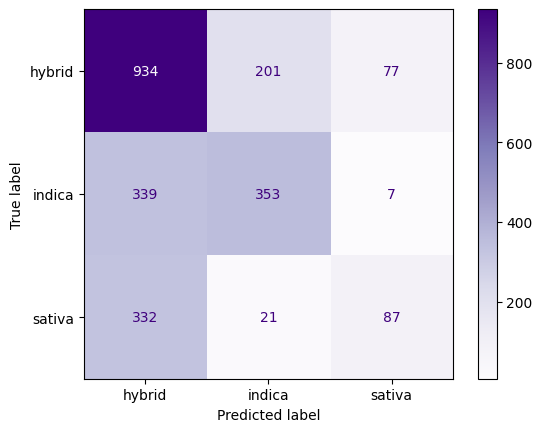

In [71]:
ConfusionMatrixDisplay.from_predictions(y2, y_pred_knn, cmap = "Purples")

**Q3 Comparison**

**Based on the results below, we see that LDA and QDA performed worse when incorporating the additional strain type, and KNN and DT also showed lower performance overall, suggesting that binary classification is more suitable for this dataset than multiclass classification.**

**The binary models performed much better because separating two groups requires learning only a single decision boundary, whereas the multiclass models must distinguish among three overlapping categories, with Hybrid strains sharing characteristics of both Indica and Sativa. In the confusion matrices, the multiclass classifiers most often confused Hybrid with Indica or Sativa due to this overlap, creating ambiguity and lowering performance. This reflects misclassification—not double counting—because Hybrid sits between the other two strains in feature space, making clear separation difficult.**

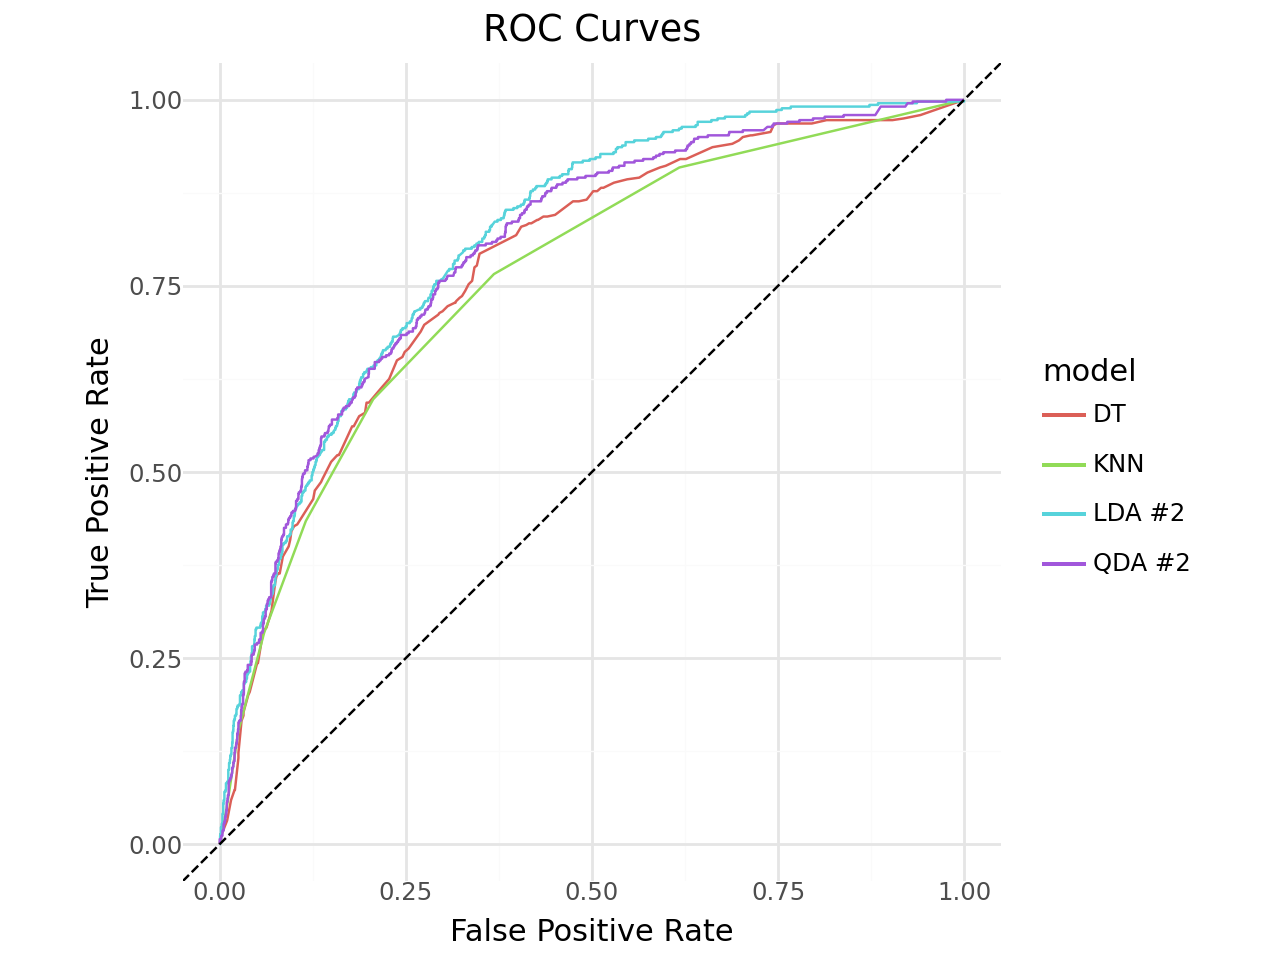

In [72]:
fpr_lda2, tpr_lda2, _ = roc_curve(y2, y_proba_lda2[:, 2], pos_label='sativa')
df_lda2 = pd.DataFrame({"model": "LDA #2", "FPR": fpr_lda2, "TPR": tpr_lda2})

fpr_qda2, tpr_qda2, _ = roc_curve(y2, y_proba_qda2[:, 2], pos_label='sativa')
df_qda2 = pd.DataFrame({"model": "QDA #2", "FPR": fpr_qda2, "TPR": tpr_qda2})

fpr_dt, tpr_dt, _ = roc_curve(y2, y_proba_dt[:, 2], pos_label='sativa')
df_dt = pd.DataFrame({"model": "DT", "FPR": fpr_dt, "TPR": tpr_dt})

fpr_knn, tpr_knn, _ = roc_curve(y2, y_proba_knn[:, 2], pos_label='sativa')
df_knn = pd.DataFrame({"model": "KNN", "FPR": fpr_knn, "TPR": tpr_knn})

roc_curve_df = pd.concat([df_lda2, df_qda2, df_dt, df_knn], ignore_index=True)

(ggplot(roc_curve_df, aes("FPR", "TPR", color="model"))
 + geom_path()
 + geom_abline(linetype="dashed")
 + coord_equal()
 + labs(title="ROC Curves", x="False Positive Rate", y="True Positive Rate")
 + theme_minimal())

In [73]:
table2 = pd.concat([result_lda2, result_qda2, result_knn, result_dt, result_lda, result_qda, result_svc, result_svm], axis=1).T
table2.sort_values(by='ROC_AUC', ascending=False).style.format({"ROC_AUC": "{:.4f}"})

,ROC_AUC
"LDA Classifier #1 (shrinkage=0.5, solver='lsqr')",0.9300
"SVC Classifier (C=0.1, probability=True)",0.9286
"SVM Classifier (C=10, degree=2, gamma='auto', kernel='poly', probability=True)",0.9286
QDA Classifier #1 (reg_param=1),0.9243
"LDA Classifier #2 (shrinkage=0.5, solver='lsqr')",0.7519
QDA Classifier #2 (reg_param=0.5),0.7422
"DT Classifier (ccp_alpha=0.001, min_samples_leaf=10, random_state=321)",0.7218
"KNN Classifier (metric='euclidean', n_neighbors=10)",0.7056


**PART 3: Multiclass Binary**

In [74]:
y_indica = (y2 == 'indica').astype(int)
y_sativa = (y2 == 'sativa').astype(int)
y_hybrid = (y2 == 'hybrid').astype(int)

**We will first work with the indica strain.**

In [75]:
log_pipe = Pipeline([
    ("ct", preprocessor),
    ("log", LogisticRegression())
])

log_pipe.fit(X2, y_indica)

Pipeline(steps=[('ct',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer()),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Rating']),
                                                 ('binary',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value=0,
                                                                                 strategy='constant'))]),
                                                  ['Creative', 'Energetic',
                                                   'Tingly', 'Euphoric',
                                                   'Relaxed', 'Aroused',
                                                   'Happy', 'Uplifted',
                                                   'Hungry', 'Talkative',
                                                   'Giggly', 'Focused',
                                                   'Sleepy', 'Dry', 'Mouth',
                                                   'Earthy', 'Sweet', 'Citrus',
                                                   'Flowery', 'Violet',
                                                   'Diesel', 'Spicy/Herbal',
                                                   'Sage', 'Woody', 'Apricot',
                                                   'Grapefruit', 'Orange',
                                                   'Pungent', 'Grape', 'Pine', ...])])),
                ('log', LogisticRegression())])

In [76]:
para_log = {"log__C": np.logspace(-3, 3, 13),
           "log__penalty":["l2"],
           "log__solver":["lbfgs","liblinear"],
           "log__max_iter": [1000]}

search_log = GridSearchCV(log_pipe, para_log, scoring=scoring, cv=CV, refit="ROC", n_jobs=-1)
log_indica = search_log.fit(X2, y_indica)

In [77]:
log_indica.best_estimator_.named_steps['log']

LogisticRegression(C=np.float64(0.1), max_iter=1000)

In [78]:
log_indica_best = Pipeline([
    ("ct", preprocessor),
    ("log", LogisticRegression(C=np.float64(0.1), max_iter=1000, solver='liblinear')) # Added missing parenthesis
])

log_indica_best.fit(X2,y_indica)

Pipeline(steps=[('ct',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer()),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Rating']),
                                                 ('binary',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value=0,
                                                                                 strategy='constant'))]),
                                                  ['Creative', 'Energetic',
                                                   'Tingly', 'Euphoric',
                                                   'Relaxed', 'Aroused',
                                                   'Happy', 'Uplifted',
                                                   'Hungry', 'Talkative',
                                                   'Giggly', 'Focused',
                                                   'Sleepy', 'Dry', 'Mouth',
                                                   'Earthy', 'Sweet', 'Citrus',
                                                   'Flowery', 'Violet',
                                                   'Diesel', 'Spicy/Herbal',
                                                   'Sage', 'Woody', 'Apricot',
                                                   'Grapefruit', 'Orange',
                                                   'Pungent', 'Grape', 'Pine', ...])])),
                ('log',
                 LogisticRegression(C=np.float64(0.1), max_iter=1000,
                                    solver='liblinear'))])

In [79]:
cv_log = cross_validate(log_indica_best, X2, y_indica, scoring=scoring, cv=CV, return_train_score=False)

result_log_indica = pd.Series({
    "ROC_AUC": cv_log["test_ROC"].mean(),
}, name="Log Indica (C=np.float64(0.1), max_iter=1000, solver='liblinear')")

result_log_indica

,"Log Indica (C=np.float64(0.1), max_iter=1000, solver='liblinear')"
ROC_AUC,0.840283


In [80]:
y_proba_log = cross_val_predict(log_indica_best, X2, y_indica, cv=CV, method="predict_proba")[:,1]
y_pred_log = cross_val_predict(log_indica_best, X2, y_indica, cv=CV, method="predict")
cm_log1 = confusion_matrix(y_indica, y_pred_log)
cm_log1

array([[1456,  196],
       [ 281,  418]])

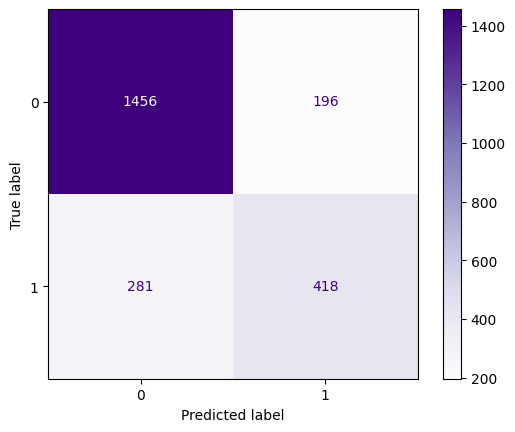

In [81]:
ConfusionMatrixDisplay.from_predictions(y_indica, y_pred_log, cmap = "Purples")

In [82]:
svc_indica = Pipeline([
    ("ct", preprocessor),
    ("svc", SVC(probability=True))
])

svc_indica.fit(X2,y_indica)

Pipeline(steps=[('ct',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer()),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Rating']),
                                                 ('binary',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value=0,
                                                                                 strategy='constant'))]),
                                                  ['Creative', 'Energetic',
                                                   'Tingly', 'Euphoric',
                                                   'Relaxed', 'Aroused',
                                                   'Happy', 'Uplifted',
                                                   'Hungry', 'Talkative',
                                                   'Giggly', 'Focused',
                                                   'Sleepy', 'Dry', 'Mouth',
                                                   'Earthy', 'Sweet', 'Citrus',
                                                   'Flowery', 'Violet',
                                                   'Diesel', 'Spicy/Herbal',
                                                   'Sage', 'Woody', 'Apricot',
                                                   'Grapefruit', 'Orange',
                                                   'Pungent', 'Grape', 'Pine', ...])])),
                ('svc', SVC(probability=True))])

In [83]:
para_svc = {
    "svc__C": [0.1, 1, 10],
    "svc__kernel": ['linear', 'rbf'],
    "svc__gamma": ['scale']
}

search_svc1 = GridSearchCV(svc_indica, para_svc, cv=CV, scoring=scoring, refit="ROC", n_jobs=-1)
svc_fit1 = search_svc1.fit(X2, y_indica)
pd.DataFrame(svc_fit1.cv_results_).sort_values(by='rank_test_ROC')

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_svc__C,param_svc__gamma,param_svc__kernel,params,split0_test_ACC,split1_test_ACC,...,std_test_F1,rank_test_F1,split0_test_ROC,split1_test_ROC,split2_test_ROC,split3_test_ROC,split4_test_ROC,mean_test_ROC,std_test_ROC,rank_test_ROC
1,1.072378,0.197191,0.158095,0.007627,0.1,scale,rbf,"{'svc__C': 0.1, 'svc__gamma': 'scale', 'svc__k...",0.802548,0.827660,...,0.021601,1,0.839933,0.859571,0.835660,0.819491,0.810931,0.833117,0.016915,1
0,0.788824,0.154198,0.112888,0.025194,0.1,scale,linear,"{'svc__C': 0.1, 'svc__gamma': 'scale', 'svc__k...",0.802548,0.812766,...,0.017122,2,0.834387,0.866113,0.824946,0.818517,0.806299,0.830052,0.020212,2
3,0.926433,0.038551,0.147553,0.006282,1.0,scale,rbf,"{'svc__C': 1, 'svc__gamma': 'scale', 'svc__ker...",0.796178,0.823404,...,0.018550,4,0.842997,0.859658,0.820725,0.817294,0.801818,0.828499,0.020391,3
2,0.703679,0.050215,0.074511,0.003703,1.0,scale,linear,"{'svc__C': 1, 'svc__gamma': 'scale', 'svc__ker...",0.798301,0.814894,...,0.016523,3,0.833394,0.866026,0.824210,0.803950,0.784221,0.822360,0.027660,4
4,1.425389,0.182994,0.089299,0.024631,10.0,scale,linear,"{'svc__C': 10, 'svc__gamma': 'scale', 'svc__ke...",0.796178,0.814894,...,0.016481,5,0.831452,0.852290,0.803799,0.811115,0.789913,0.817714,0.021883,5
5,1.358739,0.298647,0.137163,0.022864,10.0,scale,rbf,"{'svc__C': 10, 'svc__gamma': 'scale', 'svc__ke...",0.762208,0.782979,...,0.015170,6,0.791487,0.838923,0.768669,0.769004,0.757814,0.785179,0.029022,6


In [84]:
svc_fit1.best_estimator_.named_steps['svc']

SVC(C=0.1, probability=True)

In [85]:
svc_indica_best = Pipeline([
    ("ct", preprocessor),
    ("svc", SVC(C=0.1, probability=True))
])

svc_indica_best.fit(X2, y_indica)

Pipeline(steps=[('ct',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer()),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Rating']),
                                                 ('binary',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value=0,
                                                                                 strategy='constant'))]),
                                                  ['Creative', 'Energetic',
                                                   'Tingly', 'Euphoric',
                                                   'Relaxed', 'Aroused',
                                                   'Happy', 'Uplifted',
                                                   'Hungry', 'Talkative',
                                                   'Giggly', 'Focused',
                                                   'Sleepy', 'Dry', 'Mouth',
                                                   'Earthy', 'Sweet', 'Citrus',
                                                   'Flowery', 'Violet',
                                                   'Diesel', 'Spicy/Herbal',
                                                   'Sage', 'Woody', 'Apricot',
                                                   'Grapefruit', 'Orange',
                                                   'Pungent', 'Grape', 'Pine', ...])])),
                ('svc', SVC(C=0.1, probability=True))])

In [86]:
cv_svc1 = cross_validate(svc_indica_best, X2, y_indica, scoring=scoring, cv=CV, return_train_score=False)

result_svc_indica = pd.Series({
    "ROC_AUC": cv_svc1["test_ROC"].mean(),
}, name="SVC Indica (C=0.1, probability=True)")

result_svc_indica

,"SVC Indica (C=0.1, probability=True)"
ROC_AUC,0.833113


In [87]:
y_proba_svc1 = cross_val_predict(svc_indica_best, X2, y_indica, cv=CV, method="predict_proba")[:,1]
y_pred_svc1 = cross_val_predict(svc_indica_best, X2, y_indica, cv=CV, method="predict")
cm_svc1 = confusion_matrix(y_indica, y_pred_svc1)
cm_svc1

array([[1443,  209],
       [ 279,  420]])

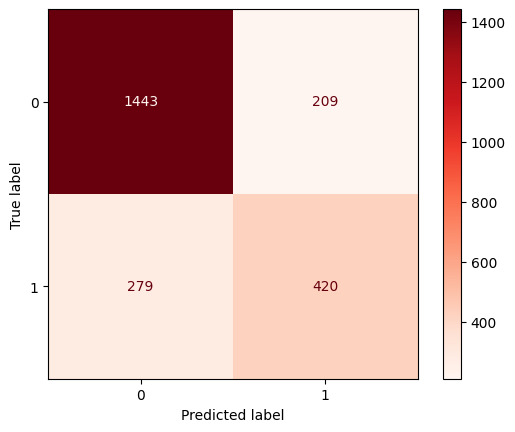

In [88]:
ConfusionMatrixDisplay.from_predictions(y_indica, y_pred_svc1, cmap = "Reds")

**We will be fitting only for Sativa**

In [89]:
log_pipe2 = Pipeline([
    ("ct", preprocessor),
    ("log", LogisticRegression())
])

log_pipe2.fit(X2,y_sativa)

Pipeline(steps=[('ct',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer()),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Rating']),
                                                 ('binary',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value=0,
                                                                                 strategy='constant'))]),
                                                  ['Creative', 'Energetic',
                                                   'Tingly', 'Euphoric',
                                                   'Relaxed', 'Aroused',
                                                   'Happy', 'Uplifted',
                                                   'Hungry', 'Talkative',
                                                   'Giggly', 'Focused',
                                                   'Sleepy', 'Dry', 'Mouth',
                                                   'Earthy', 'Sweet', 'Citrus',
                                                   'Flowery', 'Violet',
                                                   'Diesel', 'Spicy/Herbal',
                                                   'Sage', 'Woody', 'Apricot',
                                                   'Grapefruit', 'Orange',
                                                   'Pungent', 'Grape', 'Pine', ...])])),
                ('log', LogisticRegression())])

In [90]:
para_log = {"log__C": np.logspace(-3, 3, 13),
           "log__penalty":["l2"],
           "log__solver":["lbfgs","liblinear"],
           "log__max_iter": [1000]}

search_sativa = GridSearchCV(log_pipe2, para_log, scoring=scoring, cv=CV, refit="ROC", n_jobs=-1)
log_sativa = search_sativa.fit(X2, y_sativa)
pd.DataFrame(log_sativa.cv_results_).sort_values(by='rank_test_ROC')

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_log__C,param_log__max_iter,param_log__penalty,param_log__solver,params,split0_test_ACC,...,std_test_F1,rank_test_F1,split0_test_ROC,split1_test_ROC,split2_test_ROC,split3_test_ROC,split4_test_ROC,mean_test_ROC,std_test_ROC,rank_test_ROC
8,0.027735,0.002122,0.038592,0.004454,0.100000,1000,l2,lbfgs,"{'log__C': 0.1, 'log__max_iter': 1000, 'log__p...",0.828025,...,0.009291,18,0.827765,0.786783,0.842173,0.812783,0.794012,0.812703,0.020575,1
6,0.027546,0.003917,0.036845,0.000972,0.031623,1000,l2,lbfgs,"{'log__C': 0.03162277660168379, 'log__max_iter...",0.811040,...,0.016522,20,0.826252,0.789460,0.839199,0.811533,0.796957,0.812680,0.018304,2
9,0.024095,0.001114,0.036623,0.000284,0.100000,1000,l2,liblinear,"{'log__C': 0.1, 'log__max_iter': 1000, 'log__p...",0.825902,...,0.010977,17,0.823433,0.783719,0.844404,0.810403,0.794636,0.811319,0.021365,3
4,0.025252,0.001450,0.038357,0.003169,0.010000,1000,l2,lbfgs,"{'log__C': 0.01, 'log__max_iter': 1000, 'log__...",0.813163,...,0.003941,22,0.822810,0.790115,0.837741,0.807279,0.797849,0.811159,0.017190,4
10,0.030911,0.002103,0.039756,0.002512,0.316228,1000,l2,lbfgs,"{'log__C': 0.31622776601683794, 'log__max_iter...",0.830149,...,0.010414,13,0.826964,0.783035,0.843512,0.811890,0.790055,0.811091,0.022509,5
11,0.026414,0.002876,0.042372,0.005360,0.316228,1000,l2,liblinear,"{'log__C': 0.31622776601683794, 'log__max_iter...",0.830149,...,0.010363,16,0.824531,0.780090,0.845892,0.811801,0.791126,0.810688,0.023457,6
7,0.022703,0.000403,0.038189,0.002591,0.031623,1000,l2,liblinear,"{'log__C': 0.03162277660168379, 'log__max_iter...",0.813163,...,0.014037,19,0.816787,0.783719,0.840745,0.805494,0.799366,0.809223,0.019039,7
2,0.026772,0.004075,0.039386,0.002056,0.003162,1000,l2,lbfgs,"{'log__C': 0.0031622776601683794, 'log__max_it...",0.813163,...,0.000221,23,0.819517,0.788925,0.833785,0.804304,0.798385,0.808983,0.015891,8
13,0.025434,0.000524,0.037193,0.001033,1.000000,1000,l2,liblinear,"{'log__C': 1.0, 'log__max_iter': 1000, 'log__p...",0.828025,...,0.011409,15,0.823849,0.776044,0.846011,0.809391,0.786426,0.808344,0.025235,9
12,0.034805,0.005686,0.037208,0.001334,1.000000,1000,l2,lbfgs,"{'log__C': 1.0, 'log__max_iter': 1000, 'log__p...",0.830149,...,0.010489,14,0.823938,0.777413,0.845118,0.808618,0.786515,0.808320,0.024612,10


In [91]:
log_sativa.best_estimator_.named_steps['log']

LogisticRegression(C=np.float64(0.1), max_iter=1000)

In [92]:
log_sativa_best = Pipeline([
    ("ct", preprocessor),
    ("log", LogisticRegression(C=0.1, max_iter=1000, solver='liblinear'))
])

log_sativa_best.fit(X2,y_sativa)

Pipeline(steps=[('ct',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer()),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Rating']),
                                                 ('binary',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value=0,
                                                                                 strategy='constant'))]),
                                                  ['Creative', 'Energetic',
                                                   'Tingly', 'Euphoric',
                                                   'Relaxed', 'Aroused',
                                                   'Happy', 'Uplifted',
                                                   'Hungry', 'Talkative',
                                                   'Giggly', 'Focused',
                                                   'Sleepy', 'Dry', 'Mouth',
                                                   'Earthy', 'Sweet', 'Citrus',
                                                   'Flowery', 'Violet',
                                                   'Diesel', 'Spicy/Herbal',
                                                   'Sage', 'Woody', 'Apricot',
                                                   'Grapefruit', 'Orange',
                                                   'Pungent', 'Grape', 'Pine', ...])])),
                ('log',
                 LogisticRegression(C=0.1, max_iter=1000, solver='liblinear'))])

In [125]:
cv_log2 = cross_validate(log_sativa_best, X2, y_sativa, scoring=scoring, cv=CV, return_train_score=False)

result_log_sativa = pd.Series({
    "ROC_AUC": cv_log2["test_ROC"].mean(),
}, name="Log Sativa (C=0.1, max_iter=1000, solver='liblinear')")

result_log_sativa

,"Log Sativa (C=0.1, max_iter=1000, solver='liblinear')"
ROC_AUC,0.811319


In [94]:
y_proba_log2 = cross_val_predict(log_sativa_best, X2, y_sativa, cv=CV, method="predict_proba")[:,1]
y_pred_log2 = cross_val_predict(log_sativa_best, X2, y_sativa, cv=CV, method="predict")
cm_log2 = confusion_matrix(y_sativa, y_pred_log2)
cm_log2

array([[1829,   82],
       [ 326,  114]])

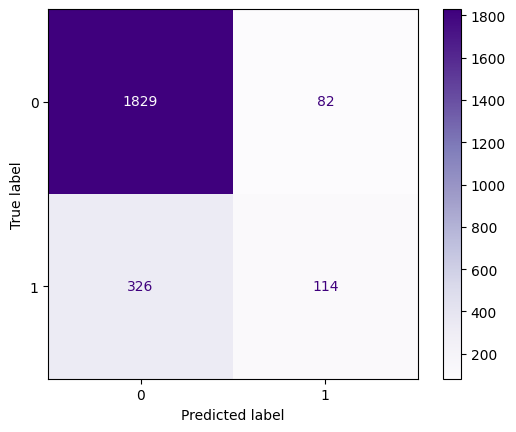

In [95]:
ConfusionMatrixDisplay.from_predictions(y_sativa, y_pred_log2, cmap = "Purples")

In [96]:
svc_sativa = Pipeline([
    ("ct", preprocessor),
    ("svc", SVC(probability=True))
])

svc_indica.fit(X2,y_sativa)

Pipeline(steps=[('ct',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer()),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Rating']),
                                                 ('binary',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value=0,
                                                                                 strategy='constant'))]),
                                                  ['Creative', 'Energetic',
                                                   'Tingly', 'Euphoric',
                                                   'Relaxed', 'Aroused',
                                                   'Happy', 'Uplifted',
                                                   'Hungry', 'Talkative',
                                                   'Giggly', 'Focused',
                                                   'Sleepy', 'Dry', 'Mouth',
                                                   'Earthy', 'Sweet', 'Citrus',
                                                   'Flowery', 'Violet',
                                                   'Diesel', 'Spicy/Herbal',
                                                   'Sage', 'Woody', 'Apricot',
                                                   'Grapefruit', 'Orange',
                                                   'Pungent', 'Grape', 'Pine', ...])])),
                ('svc', SVC(probability=True))])

In [97]:
para_svc = {
    "svc__C": [0.1, 1, 10],
    "svc__kernel": ['linear', 'rbf'],
    "svc__gamma": ['scale']
}

search_svc2 = GridSearchCV(svc_sativa, para_svc, cv=CV, scoring=scoring, refit="ROC", n_jobs=-1)
svc_fit2 = search_svc2.fit(X2, y_sativa)
pd.DataFrame(svc_fit2.cv_results_).sort_values(by='rank_test_ROC')

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_svc__C,param_svc__gamma,param_svc__kernel,params,split0_test_ACC,split1_test_ACC,...,std_test_F1,rank_test_F1,split0_test_ROC,split1_test_ROC,split2_test_ROC,split3_test_ROC,split4_test_ROC,mean_test_ROC,std_test_ROC,rank_test_ROC
2,0.680208,0.039402,0.065067,0.003007,1.0,scale,linear,"{'svc__C': 1, 'svc__gamma': 'scale', 'svc__ker...",0.813163,0.825532,...,0.013633,4,0.801389,0.769291,0.846695,0.776104,0.781161,0.794928,0.028010,1
0,0.536785,0.021965,0.063568,0.002475,0.1,scale,linear,"{'svc__C': 0.1, 'svc__gamma': 'scale', 'svc__k...",0.813163,0.812766,...,0.000221,5,0.804712,0.767893,0.825366,0.778097,0.781934,0.791600,0.020736,2
4,1.901617,0.185938,0.062009,0.002610,10.0,scale,linear,"{'svc__C': 10, 'svc__gamma': 'scale', 'svc__ke...",0.813163,0.823404,...,0.022430,3,0.803554,0.768161,0.826734,0.777026,0.780358,0.791167,0.021282,3
1,0.762381,0.018416,0.136302,0.012636,0.1,scale,rbf,"{'svc__C': 0.1, 'svc__gamma': 'scale', 'svc__k...",0.813163,0.812766,...,0.000221,5,0.786969,0.755399,0.824905,0.728418,0.772653,0.773669,0.032201,4
3,1.040888,0.186929,0.151359,0.030284,1.0,scale,rbf,"{'svc__C': 1, 'svc__gamma': 'scale', 'svc__ker...",0.815287,0.814894,...,0.008209,2,0.784773,0.759177,0.824384,0.723123,0.774230,0.773137,0.033043,5
5,1.050658,0.094759,0.132124,0.029045,10.0,scale,rbf,"{'svc__C': 10, 'svc__gamma': 'scale', 'svc__ke...",0.791932,0.804255,...,0.007161,1,0.727658,0.744631,0.772058,0.720104,0.761765,0.745243,0.019665,6


In [98]:
svc_fit2.best_estimator_.named_steps['svc']

SVC(C=1, kernel='linear', probability=True)

In [100]:
svc_sativa_best = Pipeline([
    ("ct", preprocessor),
    ("svc", SVC(C=1, kernel='linear', probability=True))
])

svc_sativa_best.fit(X2, y_sativa)

Pipeline(steps=[('ct',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer()),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Rating']),
                                                 ('binary',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value=0,
                                                                                 strategy='constant'))]),
                                                  ['Creative', 'Energetic',
                                                   'Tingly', 'Euphoric',
                                                   'Relaxed', 'Aroused',
                                                   'Happy', 'Uplifted',
                                                   'Hungry', 'Talkative',
                                                   'Giggly', 'Focused',
                                                   'Sleepy', 'Dry', 'Mouth',
                                                   'Earthy', 'Sweet', 'Citrus',
                                                   'Flowery', 'Violet',
                                                   'Diesel', 'Spicy/Herbal',
                                                   'Sage', 'Woody', 'Apricot',
                                                   'Grapefruit', 'Orange',
                                                   'Pungent', 'Grape', 'Pine', ...])])),
                ('svc', SVC(C=1, kernel='linear', probability=True))])

In [123]:
cv_svc2 = cross_validate(svc_sativa_best, X2, y_sativa, scoring=scoring, cv=CV, return_train_score=False)

result_svc_sativa = pd.Series({
    "ROC_AUC": cv_log2["test_ROC"].mean(),
}, name="SVC Sativa (C=1, kernel='linear', probability=True)")

result_svc_sativa

,"SVC Sativa (C=1, kernel='linear', probability=True)"
ROC_AUC,0.811319


In [102]:
y_proba_svc2 = cross_val_predict(svc_sativa_best, X2, y_sativa, cv=CV, method="predict_proba")[:,1]
y_pred_svc2 = cross_val_predict(svc_sativa_best, X2, y_sativa, cv=CV, method="predict")
cm_svc2 = confusion_matrix(y_sativa, y_pred_svc2)
cm_svc2

array([[1909,    2],
       [ 430,   10]])

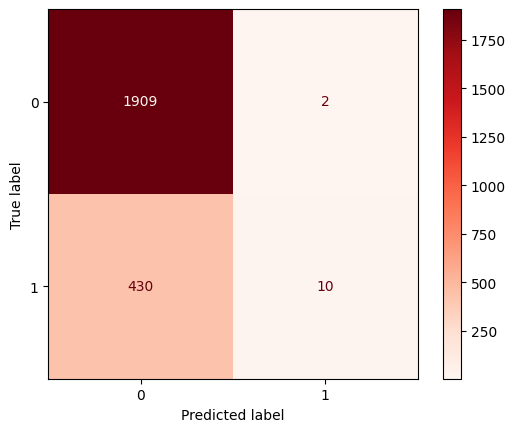

In [103]:
ConfusionMatrixDisplay.from_predictions(y_sativa, y_pred_svc2, cmap = "Reds")

**We will only be fitting for Hybrid.**

In [104]:
log_pipe3 = Pipeline([
    ("ct", preprocessor),
    ("log", LogisticRegression())
])

log_pipe3.fit(X2,y_hybrid)

Pipeline(steps=[('ct',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer()),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Rating']),
                                                 ('binary',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value=0,
                                                                                 strategy='constant'))]),
                                                  ['Creative', 'Energetic',
                                                   'Tingly', 'Euphoric',
                                                   'Relaxed', 'Aroused',
                                                   'Happy', 'Uplifted',
                                                   'Hungry', 'Talkative',
                                                   'Giggly', 'Focused',
                                                   'Sleepy', 'Dry', 'Mouth',
                                                   'Earthy', 'Sweet', 'Citrus',
                                                   'Flowery', 'Violet',
                                                   'Diesel', 'Spicy/Herbal',
                                                   'Sage', 'Woody', 'Apricot',
                                                   'Grapefruit', 'Orange',
                                                   'Pungent', 'Grape', 'Pine', ...])])),
                ('log', LogisticRegression())])

In [105]:
para_log = {"log__C": np.logspace(-3, 3, 13),
           "log__penalty":["l2"],
           "log__solver":["lbfgs","liblinear"],
           "log__max_iter": [1000]}

search_log3 = GridSearchCV(log_pipe3, para_log, scoring=scoring, cv=CV, refit="ROC", n_jobs=-1)
log_hybrid = search_log3.fit(X2, y_hybrid)
pd.DataFrame(log_hybrid.cv_results_).sort_values(by='rank_test_ROC')

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_log__C,param_log__max_iter,param_log__penalty,param_log__solver,params,split0_test_ACC,...,std_test_F1,rank_test_F1,split0_test_ROC,split1_test_ROC,split2_test_ROC,split3_test_ROC,split4_test_ROC,mean_test_ROC,std_test_ROC,rank_test_ROC
9,0.024605,0.001005,0.037636,0.000716,0.100000,1000,l2,liblinear,"{'log__C': 0.1, 'log__max_iter': 1000, 'log__p...",0.673036,...,0.021510,2,0.714533,0.658935,0.643088,0.647954,0.653708,0.663644,0.025998,1
8,0.029791,0.002737,0.043252,0.011331,0.100000,1000,l2,lbfgs,"{'log__C': 0.1, 'log__max_iter': 1000, 'log__p...",0.670913,...,0.021402,7,0.714244,0.658790,0.641529,0.648008,0.654052,0.663325,0.026111,2
7,0.024914,0.003240,0.039592,0.001861,0.031623,1000,l2,liblinear,"{'log__C': 0.03162277660168379, 'log__max_iter...",0.668790,...,0.026442,19,0.715003,0.661038,0.638430,0.645924,0.652748,0.662628,0.027232,3
6,0.027014,0.001746,0.037509,0.001644,0.031623,1000,l2,lbfgs,"{'log__C': 0.03162277660168379, 'log__max_iter...",0.668790,...,0.024815,20,0.715255,0.660258,0.636472,0.645851,0.652802,0.662128,0.027699,4
11,0.025191,0.001409,0.038080,0.001527,0.316228,1000,l2,liblinear,"{'log__C': 0.31622776601683794, 'log__max_iter...",0.666667,...,0.019830,4,0.708397,0.656632,0.644954,0.651343,0.648180,0.661901,0.023565,5
10,0.032514,0.004330,0.038146,0.002723,0.316228,1000,l2,lbfgs,"{'log__C': 0.31622776601683794, 'log__max_iter...",0.668790,...,0.021093,5,0.708595,0.656741,0.643577,0.651452,0.648543,0.661782,0.023792,6
13,0.027214,0.001498,0.043490,0.007751,1.000000,1000,l2,liblinear,"{'log__C': 1.0, 'log__max_iter': 1000, 'log__p...",0.664544,...,0.018913,6,0.700834,0.652535,0.645534,0.650419,0.641765,0.658217,0.021637,7
12,0.035678,0.002464,0.037190,0.000614,1.000000,1000,l2,lbfgs,"{'log__C': 1.0, 'log__max_iter': 1000, 'log__p...",0.664544,...,0.018661,1,0.700870,0.652517,0.645063,0.650582,0.641638,0.658134,0.021716,8
15,0.047987,0.017719,0.063808,0.024052,3.162278,1000,l2,liblinear,"{'log__C': 3.1622776601683795, 'log__max_iter'...",0.660297,...,0.015767,3,0.697188,0.651756,0.647474,0.648189,0.634877,0.655897,0.021421,9
14,0.055591,0.015194,0.056105,0.009222,3.162278,1000,l2,lbfgs,"{'log__C': 3.1622776601683795, 'log__max_iter'...",0.660297,...,0.016914,8,0.696755,0.651574,0.646875,0.647881,0.635294,0.655676,0.021250,10


In [106]:
log_hybrid.best_estimator_.named_steps['log']

LogisticRegression(C=np.float64(0.1), max_iter=1000, solver='liblinear')

In [108]:
log_hybrid_best = Pipeline([
    ("ct", preprocessor),
    ("log", LogisticRegression(C=np.float64(0.1), max_iter=1000, solver='liblinear'))
])

log_hybrid_best.fit(X2,y_hybrid)

Pipeline(steps=[('ct',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer()),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Rating']),
                                                 ('binary',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value=0,
                                                                                 strategy='constant'))]),
                                                  ['Creative', 'Energetic',
                                                   'Tingly', 'Euphoric',
                                                   'Relaxed', 'Aroused',
                                                   'Happy', 'Uplifted',
                                                   'Hungry', 'Talkative',
                                                   'Giggly', 'Focused',
                                                   'Sleepy', 'Dry', 'Mouth',
                                                   'Earthy', 'Sweet', 'Citrus',
                                                   'Flowery', 'Violet',
                                                   'Diesel', 'Spicy/Herbal',
                                                   'Sage', 'Woody', 'Apricot',
                                                   'Grapefruit', 'Orange',
                                                   'Pungent', 'Grape', 'Pine', ...])])),
                ('log',
                 LogisticRegression(C=np.float64(0.1), max_iter=1000,
                                    solver='liblinear'))])

In [109]:
cv_log3 = cross_validate(log_hybrid_best, X2, y_hybrid, scoring=scoring, cv=CV, return_train_score=False)

result_log_hybrid = pd.Series({
    "ROC_AUC": cv_log3["test_ROC"].mean(),
}, name="Log Hybrid (C=np.float64(0.1), max_iter=1000, solver='liblinear')")

result_log_hybrid

,"Log Hybrid (C=np.float64(0.1), max_iter=1000, solver='liblinear')"
ROC_AUC,0.663644


In [110]:
y_proba_log3 = cross_val_predict(log_hybrid_best, X2, y_hybrid, cv=CV, method="predict_proba")[:,1]
y_pred_log3 = cross_val_predict(log_hybrid_best, X2, y_hybrid, cv=CV, method="predict")
cm_log3 = confusion_matrix(y_hybrid, y_pred_log3)
cm_log3

array([[621, 518],
       [345, 867]])

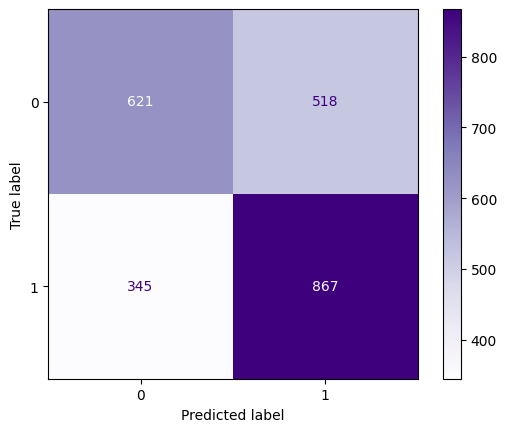

In [111]:
ConfusionMatrixDisplay.from_predictions(y_hybrid, y_pred_log3, cmap = "Purples")

In [112]:
svc_hybrid = Pipeline([
    ("ct", preprocessor),
    ("svc", SVC(probability=True))
])

svc_hybrid.fit(X2,y_hybrid)

Pipeline(steps=[('ct',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer()),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Rating']),
                                                 ('binary',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value=0,
                                                                                 strategy='constant'))]),
                                                  ['Creative', 'Energetic',
                                                   'Tingly', 'Euphoric',
                                                   'Relaxed', 'Aroused',
                                                   'Happy', 'Uplifted',
                                                   'Hungry', 'Talkative',
                                                   'Giggly', 'Focused',
                                                   'Sleepy', 'Dry', 'Mouth',
                                                   'Earthy', 'Sweet', 'Citrus',
                                                   'Flowery', 'Violet',
                                                   'Diesel', 'Spicy/Herbal',
                                                   'Sage', 'Woody', 'Apricot',
                                                   'Grapefruit', 'Orange',
                                                   'Pungent', 'Grape', 'Pine', ...])])),
                ('svc', SVC(probability=True))])

In [113]:
para_svc = {
    "svc__C": [0.1, 1, 10],
    "svc__kernel": ['linear', 'rbf'],
    "svc__gamma": ['scale']
}

search_svc3 = GridSearchCV(svc_hybrid, para_svc, cv=CV, scoring=scoring, refit="ROC", n_jobs=-1)
svc_fit3 = search_svc3.fit(X2, y_hybrid)
pd.DataFrame(svc_fit3.cv_results_).sort_values(by='rank_test_ROC')

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_svc__C,param_svc__gamma,param_svc__kernel,params,split0_test_ACC,split1_test_ACC,...,std_test_F1,rank_test_F1,split0_test_ROC,split1_test_ROC,split2_test_ROC,split3_test_ROC,split4_test_ROC,mean_test_ROC,std_test_ROC,rank_test_ROC
3,1.427323,0.064487,0.204074,0.004195,1.0,scale,rbf,"{'svc__C': 1, 'svc__gamma': 'scale', 'svc__ker...",0.677282,0.625532,...,0.025366,1,0.712385,0.664600,0.658529,0.658919,0.649793,0.668845,0.022279,1
1,1.736370,0.289526,0.254705,0.058525,0.1,scale,rbf,"{'svc__C': 0.1, 'svc__gamma': 'scale', 'svc__k...",0.651805,0.627660,...,0.021592,5,0.709642,0.655327,0.641166,0.641919,0.643287,0.658268,0.026200,2
0,1.031809,0.059304,0.106331,0.026861,0.1,scale,linear,"{'svc__C': 0.1, 'svc__gamma': 'scale', 'svc__k...",0.662420,0.634043,...,0.026556,3,0.703289,0.645121,0.639517,0.637424,0.641656,0.653401,0.025073,3
2,1.126549,0.041216,0.095243,0.004746,1.0,scale,linear,"{'svc__C': 1, 'svc__gamma': 'scale', 'svc__ker...",0.660297,0.634043,...,0.025941,2,0.688488,0.639247,0.642870,0.637134,0.644166,0.650381,0.019218,4
4,2.275793,0.260827,0.110316,0.031137,10.0,scale,linear,"{'svc__C': 10, 'svc__gamma': 'scale', 'svc__ke...",0.653928,0.636170,...,0.023597,4,0.694823,0.650505,0.623840,0.640505,0.635639,0.649062,0.024437,5
5,1.896459,0.120475,0.191802,0.036865,10.0,scale,rbf,"{'svc__C': 10, 'svc__gamma': 'scale', 'svc__ke...",0.596603,0.617021,...,0.018690,6,0.617591,0.614846,0.634062,0.631534,0.589622,0.617531,0.015846,6


In [114]:
svc_fit3.best_estimator_.named_steps['svc']

SVC(C=1, probability=True)

In [115]:
svc_hybrid_best = Pipeline([
    ("ct", preprocessor),
    ("svc", SVC(C=1, probability=True))
])

svc_hybrid_best.fit(X2, y_hybrid)

Pipeline(steps=[('ct',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer()),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Rating']),
                                                 ('binary',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value=0,
                                                                                 strategy='constant'))]),
                                                  ['Creative', 'Energetic',
                                                   'Tingly', 'Euphoric',
                                                   'Relaxed', 'Aroused',
                                                   'Happy', 'Uplifted',
                                                   'Hungry', 'Talkative',
                                                   'Giggly', 'Focused',
                                                   'Sleepy', 'Dry', 'Mouth',
                                                   'Earthy', 'Sweet', 'Citrus',
                                                   'Flowery', 'Violet',
                                                   'Diesel', 'Spicy/Herbal',
                                                   'Sage', 'Woody', 'Apricot',
                                                   'Grapefruit', 'Orange',
                                                   'Pungent', 'Grape', 'Pine', ...])])),
                ('svc', SVC(C=1, probability=True))])

In [122]:
cv_svc3 = cross_validate(svc_hybrid_best, X2, y_hybrid, scoring=scoring, cv=CV, return_train_score=False)

result_svc_hybrid = pd.Series({
    "ROC_AUC": cv_svc2["test_ROC"].mean(),
}, name="SVC Sativa (C=1, probability=True)")

result_svc_hybrid

,"SVC Sativa (C=1, probability=True)"
ROC_AUC,0.79488


In [119]:
y_proba_svc3 = cross_val_predict(svc_hybrid_best, X2, y_hybrid, cv=CV, method="predict_proba")[:,1]
y_pred_svc3 = cross_val_predict(svc_hybrid_best, X2, y_hybrid, cv=CV, method="predict")
cm_svc3 = confusion_matrix(y_hybrid, y_pred_log3)
cm_svc3

array([[621, 518],
       [345, 867]])

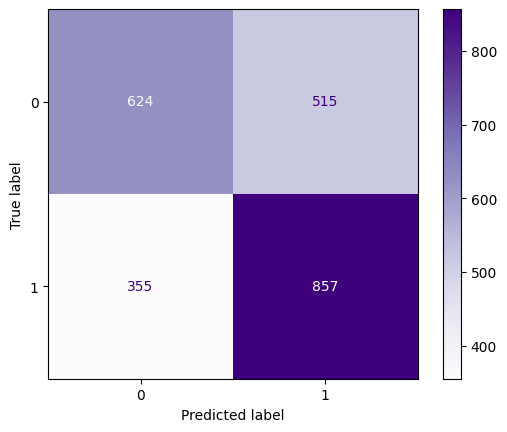

In [120]:
ConfusionMatrixDisplay.from_predictions(y_hybrid, y_pred_svc3, cmap = "Purples")

**Q2 Comparison**

In [124]:
table3 = pd.concat([result_log_indica, result_log_sativa, result_log_hybrid, result_svc_indica, result_svc_sativa, result_svc_hybrid], axis=1).T
table3.sort_values(by='ROC_AUC', ascending=False).style.format({"ROC_AUC": "{:.4f}"})

,ROC_AUC
"Log Indica (C=np.float64(0.1), max_iter=1000, solver='liblinear')",0.8403
"SVC Indica (C=0.1, probability=True)",0.8331
Log Sativa (),0.8113
"SVC Sativa (C=1, kernel='linear', probability=True)",0.8113
"SVC Sativa (C=1, probability=True)",0.7949
"Log Hybrid (C=np.float64(0.1), max_iter=1000, solver='liblinear')",0.6636


he Indica logistic model performed the best with an AUC of 0.8403, reflecting how consistently Indica strains show up in the data. The Hybrid logistic model performed the worst with an AUC of 0.6636, which makes sense because Hybrids blend characteristics of both Indica and Sativa, giving them a less distinct pattern and making them harder for the model to classify.

**OnO for each of the models. we'll begin by binning the data to have the corresponding types.**

In [131]:
#Indica and Sativa

pt3_is_df = herb_df[herb_df['Type'].isin(['sativa', 'indica'])]
X_indica_sativa = pt3_is_df.drop(columns=['Type', 'Strain', 'Effects', 'Flavor'])
y_indica_sativa = pt3_is_df['Type']

In [132]:
log_pipe_is = Pipeline([
    ("ct", preprocessor),
    ("log", LogisticRegression())
])

log_pipe_is.fit(X_indica_sativa, y_indica_sativa)

Pipeline(steps=[('ct',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer()),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Rating']),
                                                 ('binary',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value=0,
                                                                                 strategy='constant'))]),
                                                  ['Creative', 'Energetic',
                                                   'Tingly', 'Euphoric',
                                                   'Relaxed', 'Aroused',
                                                   'Happy', 'Uplifted',
                                                   'Hungry', 'Talkative',
                                                   'Giggly', 'Focused',
                                                   'Sleepy', 'Dry', 'Mouth',
                                                   'Earthy', 'Sweet', 'Citrus',
                                                   'Flowery', 'Violet',
                                                   'Diesel', 'Spicy/Herbal',
                                                   'Sage', 'Woody', 'Apricot',
                                                   'Grapefruit', 'Orange',
                                                   'Pungent', 'Grape', 'Pine', ...])])),
                ('log', LogisticRegression())])

In [133]:
para_log = {"log__C": np.logspace(-3, 3, 13),
           "log__penalty":["l2"],
           "log__solver":["lbfgs","liblinear"],
           "log__max_iter": [1000]}

search_log_is = GridSearchCV(log_pipe_is, para_log, scoring=scoring, cv=CV, refit="ROC", n_jobs=-1)
log_is = search_log_is.fit(X_indica_sativa, y_indica_sativa)
pd.DataFrame(log_is.cv_results_).sort_values(by='rank_test_ROC')

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_log__C,param_log__max_iter,param_log__penalty,param_log__solver,params,split0_test_ACC,...,std_test_F1,rank_test_F1,split0_test_ROC,split1_test_ROC,split2_test_ROC,split3_test_ROC,split4_test_ROC,mean_test_ROC,std_test_ROC,rank_test_ROC
9,0.022514,0.001823,0.039518,0.001439,0.100000,1000,l2,liblinear,"{'log__C': 0.1, 'log__max_iter': 1000, 'log__p...",0.824561,...,0.018262,1,0.920455,0.932183,0.936323,0.916112,0.943223,0.929659,0.010030,1
7,0.024158,0.004515,0.045188,0.006223,0.031623,1000,l2,liblinear,"{'log__C': 0.03162277660168379, 'log__max_iter...",0.820175,...,0.016223,7,0.921997,0.930722,0.935674,0.916518,0.942732,0.929529,0.009376,2
6,0.024696,0.002050,0.041002,0.005285,0.031623,1000,l2,lbfgs,"{'log__C': 0.03162277660168379, 'log__max_iter...",0.815789,...,0.016832,8,0.920779,0.931372,0.935755,0.916112,0.942977,0.929399,0.009793,3
8,0.024822,0.001362,0.037763,0.000577,0.100000,1000,l2,lbfgs,"{'log__C': 0.1, 'log__max_iter': 1000, 'log__p...",0.824561,...,0.017208,2,0.919968,0.931940,0.936323,0.915869,0.942896,0.929399,0.010085,4
11,0.022567,0.002554,0.044149,0.005082,0.316228,1000,l2,liblinear,"{'log__C': 0.31622776601683794, 'log__max_iter...",0.820175,...,0.020314,3,0.919805,0.931372,0.935024,0.915463,0.942405,0.928814,0.009892,5
10,0.025717,0.000684,0.039917,0.001135,0.316228,1000,l2,lbfgs,"{'log__C': 0.31622776601683794, 'log__max_iter...",0.820175,...,0.020830,4,0.920292,0.931128,0.934700,0.914894,0.942160,0.928635,0.009842,6
4,0.024083,0.001389,0.041741,0.002731,0.010000,1000,l2,lbfgs,"{'log__C': 0.01, 'log__max_iter': 1000, 'log__...",0.793860,...,0.029830,19,0.919481,0.929099,0.933726,0.914407,0.942896,0.927922,0.010131,7
5,0.022099,0.002907,0.040555,0.002144,0.010000,1000,l2,liblinear,"{'log__C': 0.01, 'log__max_iter': 1000, 'log__...",0.789474,...,0.032831,20,0.921916,0.926258,0.934537,0.914083,0.942487,0.927856,0.009862,8
2,0.023756,0.000884,0.037963,0.000703,0.003162,1000,l2,lbfgs,"{'log__C': 0.0031622776601683794, 'log__max_it...",0.776316,...,0.027996,24,0.919968,0.925122,0.933076,0.914245,0.941588,0.926800,0.009646,9
12,0.029188,0.002405,0.041697,0.004043,1.000000,1000,l2,lbfgs,"{'log__C': 1.0, 'log__max_iter': 1000, 'log__p...",0.815789,...,0.023905,6,0.916883,0.928450,0.932833,0.914164,0.939299,0.926326,0.009510,10


In [134]:
log_is.best_estimator_.named_steps['log']

LogisticRegression(C=np.float64(0.1), max_iter=1000, solver='liblinear')

In [135]:
log_best_is = Pipeline([
    ("ct", preprocessor),
    ("log", LogisticRegression(C=np.float64(0.1), max_iter=1000, solver='liblinear'))
])

log_best_is.fit(X_indica_sativa, y_indica_sativa)

Pipeline(steps=[('ct',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer()),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Rating']),
                                                 ('binary',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value=0,
                                                                                 strategy='constant'))]),
                                                  ['Creative', 'Energetic',
                                                   'Tingly', 'Euphoric',
                                                   'Relaxed', 'Aroused',
                                                   'Happy', 'Uplifted',
                                                   'Hungry', 'Talkative',
                                                   'Giggly', 'Focused',
                                                   'Sleepy', 'Dry', 'Mouth',
                                                   'Earthy', 'Sweet', 'Citrus',
                                                   'Flowery', 'Violet',
                                                   'Diesel', 'Spicy/Herbal',
                                                   'Sage', 'Woody', 'Apricot',
                                                   'Grapefruit', 'Orange',
                                                   'Pungent', 'Grape', 'Pine', ...])])),
                ('log',
                 LogisticRegression(C=np.float64(0.1), max_iter=1000,
                                    solver='liblinear'))])

In [199]:
cv_log_is = cross_validate(log_best_is, X_indica_sativa, y_indica_sativa, scoring=scoring, cv=CV, return_train_score=False)

result_log_is = pd.Series({
    "ROC_AUC": cv_log_is["test_ROC"].mean(),
}, name="LOG Indica v Sativa")

result_log_is

,LOG Indica v Sativa
ROC_AUC,0.929659


In [137]:
y_proba_log_is = cross_val_predict(log_best_is, X_indica_sativa, y_indica_sativa, cv=CV, method="predict_proba")[:,1]
y_pred_log_is = cross_val_predict(log_best_is, X_indica_sativa, y_indica_sativa, cv=CV, method="predict")
cm_log_is = confusion_matrix(y_indica_sativa, y_pred_log_is)
cm_log_is

array([[631,  68],
       [103, 337]])

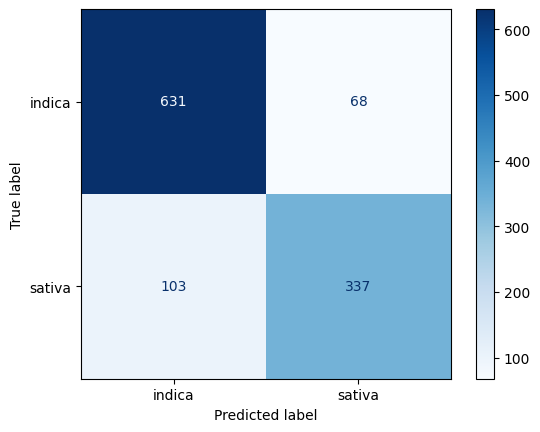

In [138]:
ConfusionMatrixDisplay.from_predictions(y_indica_sativa, y_pred_log_is, cmap = "Blues")

In [140]:
svc_pipe_is = Pipeline([
    ("ct", preprocessor),
    ("svc", SVC(probability=True))
])

svc_pipe_is.fit(X_indica_sativa,y_indica_sativa)

Pipeline(steps=[('ct',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer()),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Rating']),
                                                 ('binary',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value=0,
                                                                                 strategy='constant'))]),
                                                  ['Creative', 'Energetic',
                                                   'Tingly', 'Euphoric',
                                                   'Relaxed', 'Aroused',
                                                   'Happy', 'Uplifted',
                                                   'Hungry', 'Talkative',
                                                   'Giggly', 'Focused',
                                                   'Sleepy', 'Dry', 'Mouth',
                                                   'Earthy', 'Sweet', 'Citrus',
                                                   'Flowery', 'Violet',
                                                   'Diesel', 'Spicy/Herbal',
                                                   'Sage', 'Woody', 'Apricot',
                                                   'Grapefruit', 'Orange',
                                                   'Pungent', 'Grape', 'Pine', ...])])),
                ('svc', SVC(probability=True))])

In [141]:
para_svc = {
    "svc__C": [0.1, 1, 10],
    "svc__kernel": ['linear', 'rbf'],
    "svc__gamma": ['scale']
}

search_svc_is = GridSearchCV(svc_pipe_is, para_svc, cv=CV, scoring=scoring, refit="ROC", n_jobs=-1)
svc_is = search_svc_is.fit(X_indica_sativa, y_indica_sativa)
pd.DataFrame(svc_is.cv_results_).sort_values(by='rank_test_ROC')

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_svc__C,param_svc__gamma,param_svc__kernel,params,split0_test_ACC,split1_test_ACC,...,std_test_F1,rank_test_F1,split0_test_ROC,split1_test_ROC,split2_test_ROC,split3_test_ROC,split4_test_ROC,mean_test_ROC,std_test_ROC,rank_test_ROC
1,0.385487,0.044109,0.110453,0.030970,0.1,scale,rbf,"{'svc__C': 0.1, 'svc__gamma': 'scale', 'svc__k...",0.802632,0.855263,...,0.028651,5,0.908929,0.935755,0.937622,0.916153,0.944612,0.928614,0.013645,1
0,0.184800,0.049825,0.069405,0.024453,0.1,scale,linear,"{'svc__C': 0.1, 'svc__gamma': 'scale', 'svc__k...",0.811404,0.837719,...,0.019920,4,0.906412,0.926664,0.932265,0.915463,0.938767,0.923914,0.011624,2
3,0.255610,0.037263,0.113592,0.018235,1.0,scale,rbf,"{'svc__C': 1, 'svc__gamma': 'scale', 'svc__ker...",0.811404,0.850877,...,0.022879,2,0.903856,0.922362,0.932427,0.914570,0.940688,0.922781,0.012958,3
2,0.208709,0.053154,0.086586,0.017258,1.0,scale,linear,"{'svc__C': 1, 'svc__gamma': 'scale', 'svc__ker...",0.824561,0.850877,...,0.022962,1,0.899594,0.919115,0.927070,0.914813,0.928262,0.917771,0.010368,4
4,0.673302,0.075813,0.074406,0.027175,10.0,scale,linear,"{'svc__C': 10, 'svc__gamma': 'scale', 'svc__ke...",0.811404,0.842105,...,0.023857,3,0.893344,0.915381,0.924067,0.913352,0.923357,0.913900,0.011116,5
5,0.336770,0.018865,0.099976,0.028990,10.0,scale,rbf,"{'svc__C': 10, 'svc__gamma': 'scale', 'svc__ke...",0.789474,0.824561,...,0.022444,6,0.878084,0.890787,0.906372,0.895901,0.901529,0.894535,0.009752,6


In [142]:
svc_is.best_estimator_.named_steps['svc']

SVC(C=0.1, probability=True)

In [144]:
svc_best_is = Pipeline([
    ("ct", preprocessor),
    ("svc", SVC(C=100, kernel='linear', probability=True))
])

svc_best_is.fit(X_indica_sativa, y_indica_sativa)

Pipeline(steps=[('ct',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer()),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Rating']),
                                                 ('binary',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value=0,
                                                                                 strategy='constant'))]),
                                                  ['Creative', 'Energetic',
                                                   'Tingly', 'Euphoric',
                                                   'Relaxed', 'Aroused',
                                                   'Happy', 'Uplifted',
                                                   'Hungry', 'Talkative',
                                                   'Giggly', 'Focused',
                                                   'Sleepy', 'Dry', 'Mouth',
                                                   'Earthy', 'Sweet', 'Citrus',
                                                   'Flowery', 'Violet',
                                                   'Diesel', 'Spicy/Herbal',
                                                   'Sage', 'Woody', 'Apricot',
                                                   'Grapefruit', 'Orange',
                                                   'Pungent', 'Grape', 'Pine', ...])])),
                ('svc', SVC(C=100, kernel='linear', probability=True))])

In [202]:
cv_svc_is = cross_validate(svc_best_is, X_indica_sativa, y_indica_sativa, scoring=scoring, cv=CV, return_train_score=False)

result_svc_is = pd.Series({
    "ROC_AUC": cv_svc_is["test_ROC"].mean(),
}, name="SVC Indica v Sativa")

result_svc_is

,SVC Indica v Sativa
ROC_AUC,0.913738


In [146]:
y_proba_svc_is = cross_val_predict(svc_best_is, X_indica_sativa, y_indica_sativa, cv=CV, method="predict_proba")[:,1]
y_pred_svc_is = cross_val_predict(svc_best_is, X_indica_sativa, y_indica_sativa, cv=CV, method="predict")
cm_svc_is = confusion_matrix(y_indica_sativa, y_pred_log_is)
cm_svc_is

array([[631,  68],
       [103, 337]])

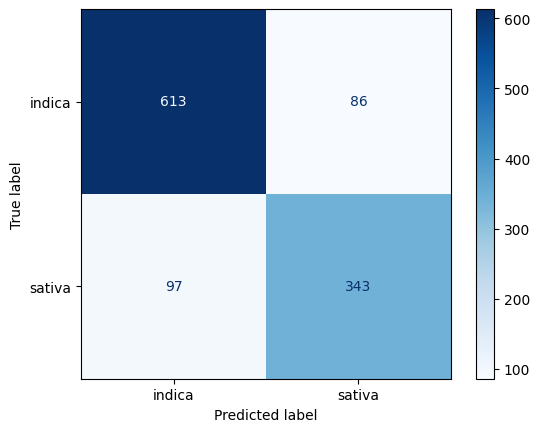

In [147]:
ConfusionMatrixDisplay.from_predictions(y_indica_sativa, y_pred_svc_is, cmap = "Blues")

In [150]:
#Indica and Hybrid
pt3_ih_df = herb_df[herb_df['Type'].isin(['indica', 'hybrid'])]
X_indica_hybrid = pt3_ih_df.drop(columns=['Type', 'Strain', 'Effects', 'Flavor'])
y_indica_hybrid = pt3_ih_df['Type']

In [151]:
log_pipe_ih = Pipeline([
    ("ct", preprocessor),
    ("log", LogisticRegression())
])

log_pipe_ih.fit(X_indica_hybrid,y_indica_hybrid)

Pipeline(steps=[('ct',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer()),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Rating']),
                                                 ('binary',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value=0,
                                                                                 strategy='constant'))]),
                                                  ['Creative', 'Energetic',
                                                   'Tingly', 'Euphoric',
                                                   'Relaxed', 'Aroused',
                                                   'Happy', 'Uplifted',
                                                   'Hungry', 'Talkative',
                                                   'Giggly', 'Focused',
                                                   'Sleepy', 'Dry', 'Mouth',
                                                   'Earthy', 'Sweet', 'Citrus',
                                                   'Flowery', 'Violet',
                                                   'Diesel', 'Spicy/Herbal',
                                                   'Sage', 'Woody', 'Apricot',
                                                   'Grapefruit', 'Orange',
                                                   'Pungent', 'Grape', 'Pine', ...])])),
                ('log', LogisticRegression())])

In [152]:
para_log = {"log__C": np.logspace(-3, 3, 13),
           "log__penalty":["l2"],
           "log__solver":["lbfgs","liblinear"],
           "log__max_iter": [1000]}

search_log_ih = GridSearchCV(log_pipe_ih, para_log, scoring=scoring, cv=CV, refit="ROC", n_jobs=-1)
log_ih = search_log_ih.fit(X_indica_hybrid, y_indica_hybrid)
pd.DataFrame(log_ih.cv_results_).sort_values(by='rank_test_ROC')

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_log__C,param_log__max_iter,param_log__penalty,param_log__solver,params,split0_test_ACC,...,std_test_F1,rank_test_F1,split0_test_ROC,split1_test_ROC,split2_test_ROC,split3_test_ROC,split4_test_ROC,mean_test_ROC,std_test_ROC,rank_test_ROC
6,0.056377,0.012918,0.087563,0.028018,0.031623,1000,l2,lbfgs,"{'log__C': 0.03162277660168379, 'log__max_iter...",0.791123,...,0.036814,7,0.839550,0.845339,0.764507,0.781272,0.804531,0.807040,0.031632,1
8,0.080770,0.030435,0.134619,0.033635,0.100000,1000,l2,lbfgs,"{'log__C': 0.1, 'log__max_iter': 1000, 'log__p...",0.791123,...,0.034545,4,0.840197,0.842023,0.763828,0.784312,0.802435,0.806559,0.030747,2
9,0.048576,0.012408,0.079218,0.024994,0.100000,1000,l2,liblinear,"{'log__C': 0.1, 'log__max_iter': 1000, 'log__p...",0.796345,...,0.036692,6,0.840197,0.841756,0.763445,0.784401,0.802878,0.806535,0.030769,3
7,0.039459,0.013360,0.065736,0.022487,0.031623,1000,l2,liblinear,"{'log__C': 0.03162277660168379, 'log__max_iter...",0.798956,...,0.037201,10,0.837199,0.842674,0.765511,0.782158,0.802878,0.806084,0.030119,4
4,0.076341,0.016094,0.091176,0.032292,0.010000,1000,l2,lbfgs,"{'log__C': 0.01, 'log__max_iter': 1000, 'log__...",0.757180,...,0.028264,22,0.835700,0.845072,0.763740,0.776136,0.802524,0.804634,0.031904,5
10,0.110682,0.042067,0.163069,0.028607,0.316228,1000,l2,lbfgs,"{'log__C': 0.31622776601683794, 'log__max_iter...",0.796345,...,0.035327,1,0.837845,0.841401,0.761733,0.782541,0.797772,0.804258,0.031080,6
11,0.072805,0.009386,0.094267,0.028280,0.316228,1000,l2,liblinear,"{'log__C': 0.31622776601683794, 'log__max_iter...",0.793734,...,0.034875,2,0.838698,0.839773,0.761496,0.782777,0.798391,0.804227,0.030893,7
5,0.039583,0.012937,0.069140,0.017689,0.010000,1000,l2,liblinear,"{'log__C': 0.01, 'log__max_iter': 1000, 'log__...",0.767624,...,0.022373,21,0.832466,0.839565,0.766130,0.779147,0.800664,0.803595,0.028766,8
13,0.036806,0.013404,0.081315,0.019011,1.000000,1000,l2,liblinear,"{'log__C': 1.0, 'log__max_iter': 1000, 'log__p...",0.788512,...,0.032418,5,0.833642,0.837108,0.760227,0.781656,0.793964,0.801319,0.029849,9
2,0.075791,0.013144,0.118826,0.008856,0.003162,1000,l2,lbfgs,"{'log__C': 0.0031622776601683794, 'log__max_it...",0.657963,...,0.024782,24,0.833613,0.841815,0.762146,0.770676,0.796325,0.800915,0.032188,10


In [153]:
log_ih.best_estimator_.named_steps['log']

LogisticRegression(C=np.float64(0.03162277660168379), max_iter=1000)

In [154]:
log_best_ih = Pipeline([
    ("ct", preprocessor),
    ("log", LogisticRegression(C=np.float64(0.03162277660168379), max_iter=1000))
])

log_best_ih.fit(X_indica_hybrid, y_indica_hybrid)

Pipeline(steps=[('ct',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer()),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Rating']),
                                                 ('binary',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value=0,
                                                                                 strategy='constant'))]),
                                                  ['Creative', 'Energetic',
                                                   'Tingly', 'Euphoric',
                                                   'Relaxed', 'Aroused',
                                                   'Happy', 'Uplifted',
                                                   'Hungry', 'Talkative',
                                                   'Giggly', 'Focused',
                                                   'Sleepy', 'Dry', 'Mouth',
                                                   'Earthy', 'Sweet', 'Citrus',
                                                   'Flowery', 'Violet',
                                                   'Diesel', 'Spicy/Herbal',
                                                   'Sage', 'Woody', 'Apricot',
                                                   'Grapefruit', 'Orange',
                                                   'Pungent', 'Grape', 'Pine', ...])])),
                ('log',
                 LogisticRegression(C=np.float64(0.03162277660168379),
                                    max_iter=1000))])

In [198]:
cv_log_ih = cross_validate(log_best_ih, X_indica_hybrid, y_indica_hybrid, scoring=scoring, cv=CV, return_train_score=False)

result_log_ih = pd.Series({
    "ROC_AUC": cv_log_ih["test_ROC"].mean(),
}, name="LOG Indica v Hybrid")

result_log_ih

,LOG Indica v Hybrid
ROC_AUC,0.80704


In [156]:
y_proba_log_ih = cross_val_predict(log_best_ih, X_indica_hybrid, y_indica_hybrid, cv=CV, method="predict_proba")[:,1]
y_pred_log_ih = cross_val_predict(log_best_ih, X_indica_hybrid, y_indica_hybrid, cv=CV, method="predict")
cm_log_ih = confusion_matrix(y_indica_hybrid, y_pred_log_ih)
cm_log_ih

array([[1031,  181],
       [ 280,  419]])

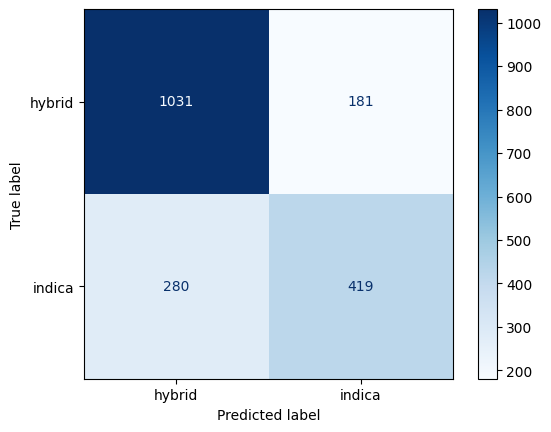

In [157]:
ConfusionMatrixDisplay.from_predictions(y_indica_hybrid, y_pred_log_ih, cmap = "Blues")

In [167]:
svc_pipe_ih = Pipeline([
    ("ct", preprocessor),
    ("svc", SVC(probability=True))
])

svc_pipe_ih.fit(X_indica_hybrid,y_indica_hybrid)

Pipeline(steps=[('ct',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer()),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Rating']),
                                                 ('binary',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value=0,
                                                                                 strategy='constant'))]),
                                                  ['Creative', 'Energetic',
                                                   'Tingly', 'Euphoric',
                                                   'Relaxed', 'Aroused',
                                                   'Happy', 'Uplifted',
                                                   'Hungry', 'Talkative',
                                                   'Giggly', 'Focused',
                                                   'Sleepy', 'Dry', 'Mouth',
                                                   'Earthy', 'Sweet', 'Citrus',
                                                   'Flowery', 'Violet',
                                                   'Diesel', 'Spicy/Herbal',
                                                   'Sage', 'Woody', 'Apricot',
                                                   'Grapefruit', 'Orange',
                                                   'Pungent', 'Grape', 'Pine', ...])])),
                ('svc', SVC(probability=True))])

In [168]:
para_svc = {
    "svc__C": [0.1, 1, 10],
    "svc__kernel": ['linear', 'rbf'],
    "svc__gamma": ['scale']
}

search_svc_ih = GridSearchCV(svc_pipe_ih, para_svc, cv=CV, scoring=scoring, refit="ROC", n_jobs=-1)
svc_ih = search_svc_ih.fit(X_indica_hybrid, y_indica_hybrid)
pd.DataFrame(svc_ih.cv_results_).sort_values(by='rank_test_ROC')

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_svc__C,param_svc__gamma,param_svc__kernel,params,split0_test_ACC,split1_test_ACC,...,std_test_F1,rank_test_F1,split0_test_ROC,split1_test_ROC,split2_test_ROC,split3_test_ROC,split4_test_ROC,mean_test_ROC,std_test_ROC,rank_test_ROC
1,0.760979,0.026958,0.142219,0.007670,0.1,scale,rbf,"{'svc__C': 0.1, 'svc__gamma': 'scale', 'svc__k...",0.796345,0.785340,...,0.030608,4,0.829409,0.840690,0.762441,0.773465,0.783442,0.797889,0.031264,1
3,0.738655,0.024834,0.124132,0.001610,1.0,scale,rbf,"{'svc__C': 1, 'svc__gamma': 'scale', 'svc__ker...",0.791123,0.785340,...,0.028149,1,0.828616,0.831927,0.763872,0.765894,0.773568,0.792776,0.030803,2
4,0.985003,0.019066,0.073738,0.007205,10.0,scale,linear,"{'svc__C': 10, 'svc__gamma': 'scale', 'svc__ke...",0.791123,0.782723,...,0.029390,5,0.825823,0.822394,0.753675,0.764950,0.761201,0.785609,0.031663,3
0,0.517554,0.075321,0.066750,0.000794,0.1,scale,linear,"{'svc__C': 0.1, 'svc__gamma': 'scale', 'svc__k...",0.785901,0.785340,...,0.027299,3,0.826705,0.801788,0.744141,0.762175,0.761969,0.779356,0.030274,4
2,0.515597,0.021755,0.071194,0.007992,1.0,scale,linear,"{'svc__C': 1, 'svc__gamma': 'scale', 'svc__ker...",0.791123,0.782723,...,0.028069,2,0.819974,0.797081,0.735139,0.763976,0.754560,0.774146,0.030446,5
5,1.670255,0.370049,0.204998,0.083421,10.0,scale,rbf,"{'svc__C': 10, 'svc__gamma': 'scale', 'svc__ke...",0.731070,0.732984,...,0.032087,6,0.770826,0.776001,0.729959,0.684283,0.738415,0.739897,0.033027,6


In [169]:
svc_ih.best_estimator_.named_steps['svc']

SVC(C=0.1, probability=True)

In [170]:
svc_best_ih = Pipeline([
    ("ct", preprocessor),
    ("svc", SVC(C=1, kernel='linear', probability=True))
])

svc_best_ih.fit(X_indica_hybrid, y_indica_hybrid)

Pipeline(steps=[('ct',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer()),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Rating']),
                                                 ('binary',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value=0,
                                                                                 strategy='constant'))]),
                                                  ['Creative', 'Energetic',
                                                   'Tingly', 'Euphoric',
                                                   'Relaxed', 'Aroused',
                                                   'Happy', 'Uplifted',
                                                   'Hungry', 'Talkative',
                                                   'Giggly', 'Focused',
                                                   'Sleepy', 'Dry', 'Mouth',
                                                   'Earthy', 'Sweet', 'Citrus',
                                                   'Flowery', 'Violet',
                                                   'Diesel', 'Spicy/Herbal',
                                                   'Sage', 'Woody', 'Apricot',
                                                   'Grapefruit', 'Orange',
                                                   'Pungent', 'Grape', 'Pine', ...])])),
                ('svc', SVC(C=1, kernel='linear', probability=True))])

In [197]:
cv_svc_ih = cross_validate(svc_best_ih, X_indica_hybrid, y_indica_hybrid, scoring=scoring, cv=CV, return_train_score=False)

result_svc_ih = pd.Series({
    "ROC_AUC": cv_svc_ih["test_ROC"].mean(),
}, name="SVC Indica v Hybrid")

result_svc_ih

,SVC Indica v Hybrid
ROC_AUC,0.774146


In [174]:
y_proba_svc_ih = cross_val_predict(svc_best_ih, X_indica_hybrid, y_indica_hybrid, cv=CV, method="predict_proba")[:,1]
y_pred_svc_ih = cross_val_predict(svc_best_ih, X_indica_hybrid, y_indica_hybrid, cv=CV, method="predict")
cm_svc_ih = confusion_matrix(y_indica_hybrid, y_pred_svc_ih)
cm_svc_ih

array([[976, 236],
       [235, 464]])

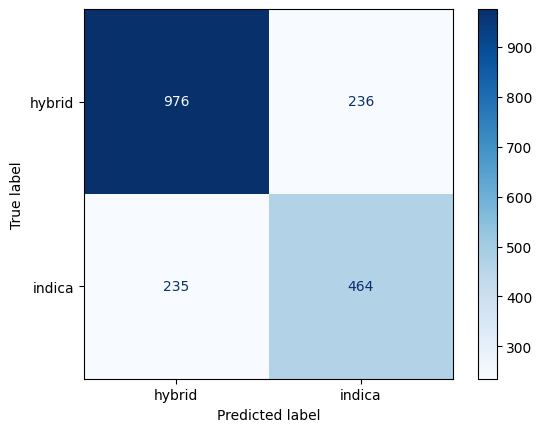

In [173]:
ConfusionMatrixDisplay.from_predictions(y_indica_hybrid, y_pred_svc_ih, cmap = "Blues")

In [178]:
#Sativa and Hybrid
pt3_hs_df = herb_df[herb_df['Type'].isin(['hybrid', 'sativa'])]
X_hybrid_sativa = pt3_hs_df.drop(columns=['Type', 'Strain', 'Effects', 'Flavor'])
y_hybrid_sativa = pt3_hs_df['Type']

In [179]:
log_pipe_hs = Pipeline([
    ("ct", preprocessor),
    ("log", LogisticRegression())
])

log_pipe_hs.fit(X_hybrid_sativa,y_hybrid_sativa)

Pipeline(steps=[('ct',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer()),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Rating']),
                                                 ('binary',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value=0,
                                                                                 strategy='constant'))]),
                                                  ['Creative', 'Energetic',
                                                   'Tingly', 'Euphoric',
                                                   'Relaxed', 'Aroused',
                                                   'Happy', 'Uplifted',
                                                   'Hungry', 'Talkative',
                                                   'Giggly', 'Focused',
                                                   'Sleepy', 'Dry', 'Mouth',
                                                   'Earthy', 'Sweet', 'Citrus',
                                                   'Flowery', 'Violet',
                                                   'Diesel', 'Spicy/Herbal',
                                                   'Sage', 'Woody', 'Apricot',
                                                   'Grapefruit', 'Orange',
                                                   'Pungent', 'Grape', 'Pine', ...])])),
                ('log', LogisticRegression())])

In [180]:
para_log = {"log__C": np.logspace(-3, 3, 13),
           "log__penalty":["l2"],
           "log__solver":["lbfgs","liblinear"],
           "log__max_iter": [1000]}

search_log_hs = GridSearchCV(log_pipe_hs, para_log, scoring=scoring, cv=CV, refit="ROC", n_jobs=-1)
log_hs = search_log_hs.fit(X_hybrid_sativa, y_hybrid_sativa)
pd.DataFrame(log_hs.cv_results_).sort_values(by='rank_test_ROC')

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_log__C,param_log__max_iter,param_log__penalty,param_log__solver,params,split0_test_ACC,...,std_test_F1,rank_test_F1,split0_test_ROC,split1_test_ROC,split2_test_ROC,split3_test_ROC,split4_test_ROC,mean_test_ROC,std_test_ROC,rank_test_ROC
6,0.091109,0.015041,0.126414,0.022632,0.031623,1000,l2,lbfgs,"{'log__C': 0.03162277660168379, 'log__max_iter...",0.767372,...,0.024633,20,0.792438,0.708707,0.754555,0.747816,0.712153,0.743134,0.030752,1
4,0.077319,0.011673,0.126536,0.023481,0.010000,1000,l2,lbfgs,"{'log__C': 0.01, 'log__max_iter': 1000, 'log__...",0.737160,...,0.003416,22,0.791082,0.709269,0.752630,0.748990,0.708772,0.742148,0.030810,2
8,0.055638,0.010847,0.089514,0.024487,0.100000,1000,l2,lbfgs,"{'log__C': 0.1, 'log__max_iter': 1000, 'log__p...",0.776435,...,0.024898,18,0.788884,0.709596,0.752583,0.742604,0.714547,0.741643,0.028683,3
9,0.046195,0.025493,0.077338,0.020873,0.100000,1000,l2,liblinear,"{'log__C': 0.1, 'log__max_iter': 1000, 'log__p...",0.788520,...,0.028907,17,0.790147,0.706650,0.752207,0.746455,0.710697,0.741231,0.030557,4
2,0.063083,0.023791,0.072195,0.019738,0.003162,1000,l2,lbfgs,"{'log__C': 0.0031622776601683794, 'log__max_it...",0.734139,...,0.000527,23,0.788183,0.708895,0.749577,0.751573,0.705438,0.740733,0.030681,5
7,0.043258,0.007798,0.070154,0.009612,0.031623,1000,l2,liblinear,"{'log__C': 0.03162277660168379, 'log__max_iter...",0.770393,...,0.024675,19,0.790614,0.704639,0.751550,0.749037,0.706705,0.740509,0.032045,6
0,0.101474,0.033753,0.126695,0.013008,0.001000,1000,l2,lbfgs,"{'log__C': 0.001, 'log__max_iter': 1000, 'log_...",0.734139,...,0.000527,23,0.786032,0.707819,0.746384,0.750493,0.703278,0.738801,0.030485,7
10,0.053791,0.024399,0.072347,0.021583,0.316228,1000,l2,lbfgs,"{'log__C': 0.31622776601683794, 'log__max_iter...",0.782477,...,0.026284,16,0.783179,0.704499,0.749906,0.737768,0.714172,0.737905,0.027832,8
11,0.063885,0.004053,0.104010,0.008347,0.316228,1000,l2,liblinear,"{'log__C': 0.31622776601683794, 'log__max_iter...",0.788520,...,0.029637,1,0.784769,0.702067,0.747370,0.740773,0.712528,0.737501,0.029057,9
5,0.099704,0.016257,0.158322,0.025700,0.010000,1000,l2,liblinear,"{'log__C': 0.01, 'log__max_iter': 1000, 'log__...",0.743202,...,0.011807,21,0.779391,0.697391,0.742675,0.745187,0.699239,0.732777,0.030990,10


In [181]:
log_hs.best_estimator_.named_steps['log']

LogisticRegression(C=np.float64(0.03162277660168379), max_iter=1000)

In [182]:
log_best_hs = Pipeline([
    ("ct", preprocessor),
    ("log", LogisticRegression(C=np.float64(0.03162277660168379), max_iter=1000))
])

log_best_hs.fit(X_hybrid_sativa, y_hybrid_sativa)

Pipeline(steps=[('ct',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer()),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Rating']),
                                                 ('binary',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value=0,
                                                                                 strategy='constant'))]),
                                                  ['Creative', 'Energetic',
                                                   'Tingly', 'Euphoric',
                                                   'Relaxed', 'Aroused',
                                                   'Happy', 'Uplifted',
                                                   'Hungry', 'Talkative',
                                                   'Giggly', 'Focused',
                                                   'Sleepy', 'Dry', 'Mouth',
                                                   'Earthy', 'Sweet', 'Citrus',
                                                   'Flowery', 'Violet',
                                                   'Diesel', 'Spicy/Herbal',
                                                   'Sage', 'Woody', 'Apricot',
                                                   'Grapefruit', 'Orange',
                                                   'Pungent', 'Grape', 'Pine', ...])])),
                ('log',
                 LogisticRegression(C=np.float64(0.03162277660168379),
                                    max_iter=1000))])

In [195]:
cv_log_hs = cross_validate(log_best_hs, X_hybrid_sativa, y_hybrid_sativa, scoring=scoring, cv=CV, return_train_score=False)

result_log_hs = pd.Series({
    "ROC_AUC": cv_log_hs["test_ROC"].mean(),
}, name="Log Hybrid v Sativa")

result_log_hs

,Log Hybrid v Sativa
ROC_AUC,0.743134


In [196]:
y_proba_log_hs = cross_val_predict(log_best_hs, X_hybrid_sativa, y_hybrid_sativa, cv=CV, method="predict_proba")[:,1]
y_pred_log_hs = cross_val_predict(log_best_hs, X_hybrid_sativa, y_hybrid_sativa, cv=CV, method="predict")
cm_log_hs = confusion_matrix(y_hybrid_sativa, y_pred_log_hs)
cm_log_hs

array([[1173,   39],
       [ 369,   71]])

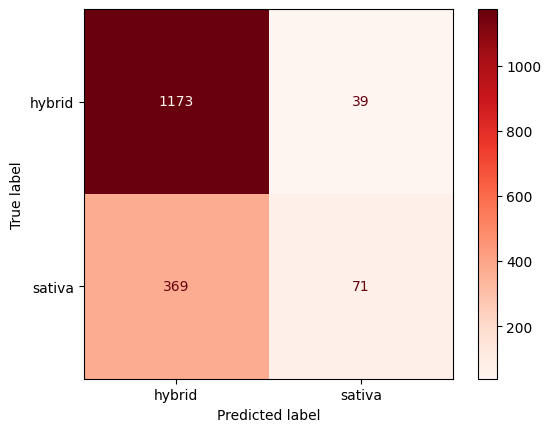

In [186]:
ConfusionMatrixDisplay.from_predictions(y_hybrid_sativa, y_pred_log_hs, cmap = "Reds")

In [188]:
svc_pipe_hs = Pipeline([
    ("ct", preprocessor),
    ("svc", SVC(probability=True))
])

svc_pipe_hs.fit(X_hybrid_sativa,y_hybrid_sativa)

Pipeline(steps=[('ct',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer()),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Rating']),
                                                 ('binary',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value=0,
                                                                                 strategy='constant'))]),
                                                  ['Creative', 'Energetic',
                                                   'Tingly', 'Euphoric',
                                                   'Relaxed', 'Aroused',
                                                   'Happy', 'Uplifted',
                                                   'Hungry', 'Talkative',
                                                   'Giggly', 'Focused',
                                                   'Sleepy', 'Dry', 'Mouth',
                                                   'Earthy', 'Sweet', 'Citrus',
                                                   'Flowery', 'Violet',
                                                   'Diesel', 'Spicy/Herbal',
                                                   'Sage', 'Woody', 'Apricot',
                                                   'Grapefruit', 'Orange',
                                                   'Pungent', 'Grape', 'Pine', ...])])),
                ('svc', SVC(probability=True))])

In [189]:
para_svc = {
    "svc__C": [0.1, 1, 10],
    "svc__kernel": ['linear', 'rbf'],
    "svc__gamma": ['scale']
}

search_svc_hs = GridSearchCV(svc_pipe_hs, para_svc, cv=CV, scoring=scoring, refit="ROC", n_jobs=-1)
svc_hs = search_svc_hs.fit(X_hybrid_sativa, y_hybrid_sativa)
pd.DataFrame(svc_hs.cv_results_).sort_values(by='rank_test_ROC')

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_svc__C,param_svc__gamma,param_svc__kernel,params,split0_test_ACC,split1_test_ACC,...,std_test_F1,rank_test_F1,split0_test_ROC,split1_test_ROC,split2_test_ROC,split3_test_ROC,split4_test_ROC,mean_test_ROC,std_test_ROC,rank_test_ROC
0,0.352396,0.021427,0.059503,0.002414,0.1,scale,linear,"{'svc__C': 0.1, 'svc__gamma': 'scale', 'svc__k...",0.719033,0.737160,...,0.003827,5,0.746423,0.697811,0.731640,0.735514,0.724221,0.727122,0.016315,1
2,0.734966,0.125863,0.132908,0.036085,1.0,scale,linear,"{'svc__C': 1, 'svc__gamma': 'scale', 'svc__ker...",0.719033,0.737160,...,0.036038,4,0.741746,0.696689,0.732438,0.736875,0.715322,0.724614,0.016560,2
4,2.164718,0.313844,0.105792,0.027987,10.0,scale,linear,"{'svc__C': 10, 'svc__gamma': 'scale', 'svc__ke...",0.719033,0.731118,...,0.038288,3,0.744552,0.693556,0.731593,0.737228,0.703160,0.722018,0.019982,3
1,0.525957,0.023561,0.110343,0.020043,0.1,scale,rbf,"{'svc__C': 0.1, 'svc__gamma': 'scale', 'svc__k...",0.734139,0.734139,...,0.000527,6,0.755027,0.677352,0.737955,0.723117,0.716285,0.721947,0.025972,4
3,0.848557,0.105779,0.144547,0.040099,1.0,scale,rbf,"{'svc__C': 1, 'svc__gamma': 'scale', 'svc__ker...",0.785498,0.719033,...,0.026436,1,0.754863,0.671904,0.736382,0.721943,0.712153,0.719449,0.027788,5
5,1.348599,0.141501,0.196896,0.096210,10.0,scale,rbf,"{'svc__C': 10, 'svc__gamma': 'scale', 'svc__ke...",0.734139,0.700906,...,0.019197,2,0.717920,0.629536,0.724267,0.703677,0.672333,0.689547,0.034951,6


In [190]:
svc_hs.best_estimator_.named_steps['svc']

SVC(C=0.1, kernel='linear', probability=True)

In [191]:
svc_best_hs = Pipeline([
    ("ct", preprocessor),
    ("svc", SVC(C=1, kernel='linear', probability=True))
])

svc_best_hs.fit(X_hybrid_sativa, y_hybrid_sativa)

Pipeline(steps=[('ct',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer()),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Rating']),
                                                 ('binary',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value=0,
                                                                                 strategy='constant'))]),
                                                  ['Creative', 'Energetic',
                                                   'Tingly', 'Euphoric',
                                                   'Relaxed', 'Aroused',
                                                   'Happy', 'Uplifted',
                                                   'Hungry', 'Talkative',
                                                   'Giggly', 'Focused',
                                                   'Sleepy', 'Dry', 'Mouth',
                                                   'Earthy', 'Sweet', 'Citrus',
                                                   'Flowery', 'Violet',
                                                   'Diesel', 'Spicy/Herbal',
                                                   'Sage', 'Woody', 'Apricot',
                                                   'Grapefruit', 'Orange',
                                                   'Pungent', 'Grape', 'Pine', ...])])),
                ('svc', SVC(C=1, kernel='linear', probability=True))])

In [194]:
cv_svc_hs = cross_validate(svc_best_hs, X_hybrid_sativa, y_hybrid_sativa, scoring=scoring, cv=CV, return_train_score=False)

result_svc_hs = pd.Series({
    "ROC_AUC": cv_svc_hs["test_ROC"].mean(),
}, name="SVC Hybrid v Sativa")

result_svc_hs

,SVC Hybrid v Sativa
ROC_AUC,0.724619


In [193]:
y_proba_svc_hs = cross_val_predict(svc_best_hs, X_hybrid_sativa, y_hybrid_sativa, cv=CV, method="predict_proba")[:,1]
y_pred_svc_hs = cross_val_predict(svc_best_hs, X_hybrid_sativa, y_hybrid_sativa, cv=CV, method="predict")
cm_svc_hs = confusion_matrix(y_hybrid_sativa, y_pred_svc_hs)
cm_svc_hs

array([[1150,   62],
       [ 359,   81]])

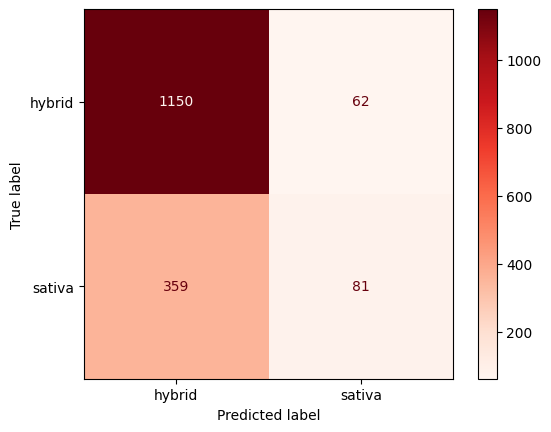

In [200]:
ConfusionMatrixDisplay.from_predictions(y_hybrid_sativa, y_pred_svc_hs, cmap = "Reds")

**Q4 Comparison OnO**

In [203]:
table4 = pd.concat([result_log_is, result_log_ih, result_log_hs, result_svc_is, result_svc_ih, result_svc_hs], axis=1).T
table4.sort_values(by='ROC_AUC', ascending=False).style.format({"ROC_AUC": "{:.4f}"})

,ROC_AUC
LOG Indica v Sativa,0.9297
SVC Indica v Sativa,0.9137
LOG Indica v Hybrid,0.8070
SVC Indica v Hybrid,0.7741
Log Hybrid v Sativa,0.7431
SVC Hybrid v Sativa,0.7246


**In comparison to OvR, the OnO models prioritized the Indica and Sativa pair opposed to a single strain being paired up with hybrid. For similiar reasons as in OvR, it is likely that hybrid has an overlap and leads to not correctly identifying the straining compared to a binary model. As a result, it is not surprising that Log did the best in terms of classification as it may pick up on the subtlties of each strain in a binary classification such that hybrid is not included. **

**Q5**

**If we were given a logistic regression such that there were 3 classes, this would utilize an OvR approach since it fits the probability against all classes while SVC would incorporate a OvO because they work with binary classifiers such that our data would have to ensure our dependant or target variable is made into pairs.**